# Φ8-resistant picks vs their parents — 9-2-1 r1 and 9-6-2 r1

**Question.** Plasmidsaurus order **SBYK6W** returned complete genomes of one Φ8-resistant pick per host
(`921_mut` = 9-2-1 R1, `962_mut` = 9-6-2 R1). What changed relative to the parent, and does it touch a
surface polysaccharide (O-antigen, LPS core, capsule) that Φ8's depolymerase could use as receptor?

**Inputs**

| label | what | assembly | reads |
|---|---|---|---|
| `921_wt` | 9-2-1 parent (GCA_059295275.1) | `data/bacteria_genome/9-2-1/` | SRA SRR39379361 (ONT, `data/bacteria_genome/9-2-1/reads/`) + host reads inside the Φ8 Illumina run (3NKSC3) |
| `962_wt` | 9-6-2 parent, **rerun** (canonical) | `data/bacteria_genome/9-6-2/rerun_QB9Y48/` | not available |
| `962_wt_orig` | 9-6-2 parent, original run (24×) — **noise control only** | `data/bacteria_genome/9-6-2/original_XH254M/` | not available |
| `921_mut` | 9-2-1 R1, Φ8-resistant pick | `data/bacteria_genome/9-2-1/resistant_r1_SBYK6W/` | same folder (`*.fastq.gz`) |
| `962_mut` | 9-6-2 R1, Φ8-resistant pick | `data/bacteria_genome/9-6-2/resistant_r1_SBYK6W/` | same folder (`*.fastq.gz`) |

**Read this before the results**
- 9-2-1 and 9-6-2 are **the same clone** (100% ANI, `code/0627_unique_strain_table.ipynb`). So every genome here is
  put on **one coordinate frame — the 9-2-1 parent** — and all positions below are 1-based 9-2-1 coordinates.
- All five assemblies are **ONT-only** (Plasmidsaurus: Autocycler/Flye + Medaka). ONT consensus still makes systematic
  errors in homopolymers and at some sequence motifs. Two assemblies of the *same* clone already differ at a handful of
  sites, so an assembly-vs-assembly difference is **not** a mutation until reads back it (§4).
- The R picks were **never phenotypically confirmed as resistant** (`documents/2026-10-05_last_2_week_lab_planning.md`:
  “not sure if contamination or real colonies”; no PIA readout recorded). R1 is a pick number, not a known plate position.
- Heavy steps (read mapping) run in `map_reads.sh`; this notebook reads the BAMs it produces and caches pileup scans.

Run with the `igem2026` conda env (needs `minimap2`, `samtools`, `pycirclize`, `pygenomeviz`, Biopython).

In [1]:
import gzip, hashlib, re, shutil, subprocess, sys, yaml
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import SeqIO
from Bio.Seq import Seq

pd.set_option("display.max_colwidth", 70, "display.width", 200, "display.max_rows", 200)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/bacteria_genome").is_dir())
OUT = ROOT / "code/output/1010_resistant_mutant_comparison"
BAM = OUT / "bam"
OUT.mkdir(parents=True, exist_ok=True)

def tool(name):
    return shutil.which(name) or str(Path(sys.prefix) / "bin" / name)
MINIMAP2, SAMTOOLS = tool("minimap2"), tool("samtools")

# label -> (assembly folder, file prefix glob)
GENOMES = {
    "921_wt":      ROOT / "data/bacteria_genome/9-2-1",
    "962_wt":      ROOT / "data/bacteria_genome/9-6-2/rerun_QB9Y48",
    "962_wt_orig": ROOT / "data/bacteria_genome/9-6-2/original_XH254M",
    "921_mut":     ROOT / "data/bacteria_genome/9-2-1/resistant_r1_SBYK6W",
    "962_mut":     ROOT / "data/bacteria_genome/9-6-2/resistant_r1_SBYK6W",
}
REF = "921_wt"                       # single coordinate frame
LINEAGES = {"921": ("921_wt", "921_mut"), "962": ("962_wt", "962_mut")}

def one(d, pattern):
    hits = [p for p in sorted(d.glob(pattern)) if "hypothetical" not in p.name and "inference" not in p.name]
    assert len(hits) == 1, (d, pattern, hits)
    return hits[0]

FILES = {k: {
    "fasta": one(d, "*_1_reference.fasta"),
    "gbff":  one(d, "annotation/*_reference.gbff"),
    "tsv":   one(d, "annotation/*_reference.tsv"),
    "faa":   one(d, "annotation/*_reference.faa"),
    "txt":   one(d, "annotation/*_reference.txt"),
    "stats": one(d, "*_ont-stats.tsv"),
    "checkm": one(d, "*_checkm-results.tsv"),
    "sourmash": one(d, "*_sourmash-genome-species.csv"),
    "yaml":  one(d, "*_prepolished-assembly-info.yaml"),
} for k, d in GENOMES.items()}

SEQ = {k: str(next(SeqIO.parse(f["fasta"], "fasta")).seq).upper() for k, f in FILES.items()}
print(MINIMAP2, SAMTOOLS, sep="\n")

/opt/anaconda3/envs/igem2026/bin/minimap2
/opt/anaconda3/envs/igem2026/bin/samtools


## 0. Provenance — input checksums
So any later re-delivery of the same order can be checked against what this notebook analysed.

In [2]:
def md5(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as fh:
        for b in iter(lambda: fh.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

prov = pd.DataFrame([{"label": k, "fasta": str(f["fasta"].relative_to(ROOT)), "md5": md5(f["fasta"])}
                     for k, f in FILES.items()])
prov.to_csv(OUT / "input_md5.tsv", sep="\t", index=False)
prov

,label,fasta,md5
0,921_wt,data/bacteria_genome/9-2-1/XH254M_1_sample_1_1_reference.fasta,9e56661d6cd78c5d9565e291efca4533
1,962_wt,data/bacteria_genome/9-6-2/rerun_QB9Y48/QB9Y48_1_rerun_sample_2_2_...,6abe245651050ef760cc529ed497b65d
2,962_wt_orig,data/bacteria_genome/9-6-2/original_XH254M/XH254M_2_sample_2_1_ref...,2da8b061bd6c0d5efcada6c3f9e0e868
3,921_mut,data/bacteria_genome/9-2-1/resistant_r1_SBYK6W/SBYK6W_1_sample_1_9...,6f76700de12509f7fecb503fc0c8cfb8
4,962_mut,data/bacteria_genome/9-6-2/resistant_r1_SBYK6W/SBYK6W_2_sample_2_9...,ef7aed81b9b683234be7d210286b8d4c


## 1. Assembly QC — five assemblies side by side
All numbers are read from the vendor/Bakta files, not recomputed. `est_cov` is the depth of the read subset the
assembler used; `raw_cov` is all delivered reads.

In [3]:
def kv_tsv(p):
    return dict(l.rstrip("\n").split("\t", 1) for l in open(p) if "\t" in l)

def bakta_counts(p):
    d = {}
    for l in open(p):
        if ":" in l:
            k, v = l.split(":", 1)
            d[k.strip()] = v.strip()
    return d

rows = []
for k, f in FILES.items():
    st = kv_tsv(f["stats"]); cm = pd.read_csv(f["checkm"], sep="\t").iloc[0]
    sm = pd.read_csv(f["sourmash"]).iloc[0]; y = yaml.safe_load(open(f["yaml"])); b = bakta_counts(f["txt"])
    rows.append({
        "label": k, "length_bp": len(SEQ[k]),
        "contigs": y["consensus_assembly_unitigs"], "topology": y["consensus_assembly_clusters"][0]["topology"],
        "raw_cov": float(st["est_cov_raw"]), "est_cov": float(st["est_cov"]),
        "read_N50": int(st["rNG50"]) if "rNG50" in st else None, "median_phred": float(st["median_phred"]),
        "checkm_compl": cm["Completeness"], "checkm_contam": cm["Contamination"],
        "gtdb_species": sm["lineage"].split(";")[-1], "ani_to_gtdb": round(sm["query_ani_at_rank"], 4),
        "CDS": int(b["CDSs"]), "tRNA": int(b["tRNAs"]), "rRNA": int(b["rRNAs"]),
        "pseudogenes": int(b["pseudogenes"]), "hypotheticals": int(b["hypotheticals"]),
    })
qc = pd.DataFrame(rows).set_index("label")
qc.to_csv(OUT / "assembly_qc.tsv", sep="\t")
qc

,length_bp,contigs,topology,raw_cov,est_cov,read_N50,median_phred,checkm_compl,checkm_contam,gtdb_species,ani_to_gtdb,CDS,tRNA,rRNA,pseudogenes,hypotheticals
label,,,,,,,,,,,,,,,,
921_wt,6178779,1,circular,313.1,94.0,66805,25.79,99.74,1.94,s__Pseudomonas_E sp013179515,0.9953,5449,74,22,11,233
962_wt,6178775,1,circular,70.4,66.9,51165,24.16,99.74,1.94,s__Pseudomonas_E sp013179515,0.9953,5448,74,22,11,232
962_wt_orig,6178790,1,circular,25.5,24.2,48206,24.50,99.74,1.94,s__Pseudomonas_E sp013179515,0.9953,5448,74,22,11,238
921_mut,6178778,1,circular,415.2,95.1,63344,24.56,99.74,1.94,s__Pseudomonas_E sp013179515,0.9953,5452,74,22,11,236
962_mut,6178774,1,circular,248.3,95.8,62255,24.40,99.70,1.94,s__Pseudomonas_E sp013179515,0.9953,5451,74,22,11,235


**Reading.** Every assembly is one closed circular chromosome of 6,178,774–6,178,790 bp, same GTDB species, same
CheckM profile. The length spread (16 bp) is already the first hint that differences are small indels, not
gene gains/losses. `962_wt_orig` is the low-depth run (24×) and is used only to measure assembly noise.

## 2. Whole-genome alignment — every assembly onto the 9-2-1 parent
`minimap2 -x asm5 -c --cs` aligns each assembly to `921_wt`; the `cs` tag is parsed into SNVs and indels.
Indels are **left-normalised** (shifted to the leftmost equivalent position) so the same homopolymer slip in two
assemblies lands on the same coordinate.

In [4]:
REF_SEQ = SEQ[REF]
REF_FA = FILES[REF]["fasta"]

def run_paf(query_fa):
    out = subprocess.run([MINIMAP2, "-x", "asm5", "-c", "--cs", "-t", "8", str(REF_FA), str(query_fa)],
                         capture_output=True, text=True, check=True).stdout
    return [l.split("\t") for l in out.splitlines()]

def left_norm(ref, pos, rall, aall):
    # pos: 0-based start on ref; deletion rall != '' / aall == ''; insertion before pos: rall == '' / aall != ''
    if rall and not aall:
        n = len(rall)
        while pos > 0 and ref[pos - 1] == ref[pos + n - 1]:
            pos -= 1
        return pos, ref[pos:pos + n], ""
    if aall and not rall:
        while pos > 0 and ref[pos - 1] == aall[-1]:
            aall = aall[-1] + aall[:-1]
            pos -= 1
        return pos, "", aall
    return pos, rall, aall

CS = re.compile(r"(:\d+|\*[a-z]{2}|\+[a-z]+|-[a-z]+)")

def cs_variants(paf_rows, ref):
    vs, aligned = [], np.zeros(len(ref), bool)
    for r in paf_rows:
        tags = dict(t.split(":", 2)[0::2] for t in r[12:])
        if tags.get("tp") != "P":
            continue
        assert r[4] == "+", "assembly aligned on reverse strand"
        t = int(r[7]); aligned[int(r[7]):int(r[8])] = True
        for op in CS.findall(tags["cs"]):
            if op[0] == ":":
                t += int(op[1:])
            elif op[0] == "*":
                vs.append((t, op[1].upper(), op[2].upper())); t += 1
            elif op[0] == "+":
                vs.append(left_norm(ref, t, "", op[1:].upper()))
            else:
                d = op[1:].upper(); vs.append(left_norm(ref, t, d, "")); t += len(d)
    return vs, aligned

VARS, COVERED = {}, {}
for k in FILES:
    if k == REF:
        continue
    VARS[k], COVERED[k] = cs_variants(run_paf(FILES[k]["fasta"]), REF_SEQ)

pd.DataFrame([{"query": k, "ref": REF, "aligned_fraction_of_ref": round(COVERED[k].mean(), 6),
               "n_diffs": len(v), "SNV": sum(1 for _, a, b in v if len(a) == len(b) == 1),
               "indel": sum(1 for _, a, b in v if len(a) != len(b)),
               "net_length_change": sum(len(b) - len(a) for _, a, b in v)} for k, v in VARS.items()])

,query,ref,aligned_fraction_of_ref,n_diffs,SNV,indel,net_length_change
0,962_wt,921_wt,1.0,11,5,6,-4
1,962_wt_orig,921_wt,1.0,49,17,32,11
2,921_mut,921_wt,1.0,16,9,7,-1
3,962_mut,921_wt,1.0,18,9,9,-5


**Structural check.** Aligned fraction ≈ 1.0 for every assembly → one colinear alignment end to end: **no
inversion, deletion, insertion or rearrangement** larger than a few bp in either mutant. `net_length_change` matches
the length differences in §1, so nothing is hidden outside the aligned blocks.

Independent cross-check of the diff counts with a plain exact-match walk (no aligner; written for this notebook
during planning). It should find the same number of differences per pair as minimap2.

In [5]:
def anchor_walk(a, b, K=31):
    # walk two near-identical, same-origin sequences; at each mismatch resync on the next K-mer of a found in b
    i = j = 0; out = []
    while i < len(a) and j < len(b):
        step = 4096
        while step >= 1:
            while i + step <= len(a) and j + step <= len(b) and a[i:i + step] == b[j:j + step]:
                i += step; j += step
            step //= 2
        if i >= len(a) or j >= len(b):
            break
        for off in range(1, 5000):
            km = a[i + off:i + off + K]
            if len(km) < K:
                break
            p = b.find(km, j, j + off + 5000)
            if p >= j:
                out.append(i); i += off; j = p; break
        else:
            raise RuntimeError(f"lost sync at {i}")
    return out

walk = {k: len(anchor_walk(REF_SEQ, SEQ[k])) for k in VARS}
# the walk merges adjacent edits (e.g. CT->TC) into one event; collapse minimap2 calls the same way
def n_events(vs, gap=1):
    ps = sorted(p for p, _, _ in vs); return sum(1 for i, p in enumerate(ps) if i == 0 or p - ps[i - 1] > gap)
pd.DataFrame({"anchor_walk_events": walk, "minimap2_events": {k: n_events(v) for k, v in VARS.items()}})

,anchor_walk_events,minimap2_events
962_wt,10,10
962_wt_orig,45,47
921_mut,15,15
962_mut,18,18


### 2b. Φ8 is not in any genome
Resistance by lysogeny (Φ8 integrated or carried as a plasmid-prophage → superinfection immunity) would show up as
Φ8 sequence in the mutant. 31-mers sampled every 100 bp along the Φ8 genome are searched in both strands.

In [6]:
phage = str(next(SeqIO.parse(ROOT / "data/phage_genome/9-2-1/assembly/phage_genome.fasta", "fasta")).seq).upper()
kmers = [phage[i:i + 31] for i in range(0, len(phage) - 31, 100)]
phi = []
for k, s in SEQ.items():
    rc = str(Seq(s).reverse_complement())
    phi.append({"genome": k, "phi8_31mers_found": sum(1 for m in kmers if m in s or m in rc), "of": len(kmers)})
pd.DataFrame(phi)

,genome,phi8_31mers_found,of
0,921_wt,0,624
1,962_wt,0,624
2,962_wt_orig,0,624
3,921_mut,0,624
4,962_mut,0,624


## 3. One allele table across all five assemblies
Every site that differs in any assembly is listed once, with the allele each assembly carries (`.` = same as the
9-2-1 parent). Each site then gets:

- **`lineage_change`** — which lineage(s) changed between parent and mutant
  (`921`: `921_mut` ≠ `921_wt`; `962`: `962_mut` ≠ `962_wt` rerun).
- **`site_class`**
  - `parents disagree` — the three parent assemblies (`921_wt`, `962_wt`, `962_wt_orig`) of one clone do not agree:
    the site is assembly-noise-prone by definition.
  - `both mutants, no parent` — both mutants carry the same new allele. They were sequenced **in the same run**, so a
    shared basecalling/consensus error is the default explanation, not convergent selection.
  - `one lineage only` — the only class that could be a real, lineage-specific mutation.
- **`homopolymer`** — longest single-base run touching the site (≥5 is a classic ONT error zone).
- **coding effect** of the non-reference allele, from the 9-2-1 Bakta annotation (strand-aware, translation table 11).

In [7]:
LABELS = ["921_wt", "962_wt", "962_wt_orig", "921_mut", "962_mut"]

def allele_str(r, a):
    if len(r) == len(a) == 1: return f"{r}>{a}"
    if r and not a:            return f"del{r}"
    return f"ins{a}"

geno = defaultdict(dict)
for k, vs in VARS.items():
    for p, r, a in vs:
        geno[p][k] = allele_str(r, a)
sites = sorted(geno)

def hp_run(pos):
    # longest homopolymer touching [pos-1, pos+1]
    best = 1
    for c in {pos - 1, pos, pos + 1}:
        if not 0 <= c < len(REF_SEQ): continue
        b = REF_SEQ[c]; l = r = c
        while l > 0 and REF_SEQ[l - 1] == b: l -= 1
        while r < len(REF_SEQ) - 1 and REF_SEQ[r + 1] == b: r += 1
        best = max(best, r - l + 1)
    return best

rows = []
for p in sites:
    g = {k: geno[p].get(k, ".") for k in LABELS}
    parents_agree = g["921_wt"] == g["962_wt"] == g["962_wt_orig"]
    ch921, ch962 = g["921_mut"] != g["921_wt"], g["962_mut"] != g["962_wt"]
    lin = "+".join([x for x, c in (("921", ch921), ("962", ch962)) if c]) or "-"
    if not (ch921 or ch962):
        cls = "parent-only difference"
    elif not parents_agree:
        cls = "parents disagree"
    elif ch921 and ch962 and g["921_mut"] == g["962_mut"]:
        cls = "both mutants, no parent"
    else:
        cls = "one lineage only"
    rows.append({"pos": p + 1, **g, "lineage_change": lin, "site_class": cls, "homopolymer": hp_run(p),
                 "context": REF_SEQ[max(0, p - 10):p].lower() + REF_SEQ[p:p + 1] + REF_SEQ[p + 1:p + 11].lower()})
AT = pd.DataFrame(rows)
AT["site_class"].value_counts()

site_class
parent-only difference     36
parents disagree           17
one lineage only           15
both mutants, no parent     1
Name: count, dtype: int64

### 3b. Coding effect
For each site the non-reference allele is applied to the 9-2-1 sequence and the overlapping CDS is re-translated.
Intergenic sites report the nearest genes on both sides and whether the site is within 150 bp upstream of a start
codon (possible promoter / RBS effect).

In [8]:
gb = next(SeqIO.parse(FILES[REF]["gbff"], "genbank"))
CDS = []
for f in gb.features:
    if f.type != "CDS" or len(f.location.parts) != 1:
        continue
    q = f.qualifiers
    CDS.append({"start": int(f.location.start), "end": int(f.location.end), "strand": f.location.strand,
                "locus": q.get("locus_tag", [""])[0], "gene": q.get("gene", [""])[0],
                "product": q.get("product", [""])[0]})
CDS = pd.DataFrame(CDS).sort_values("start").reset_index(drop=True)

def apply(seq, p, r, a):
    assert seq[p:p + len(r)] == r
    return seq[:p] + a + seq[p + len(r):]

def parse_allele(s):
    if ">" in s: r, a = s.split(">"); return r, a
    if s.startswith("del"): return s[3:], ""
    return "", s[3:]

def effect(p, allele):
    r, a = parse_allele(allele)
    hit = CDS[(CDS.start <= p) & (p < CDS.end)]
    if hit.empty:
        up = CDS[CDS.end <= p].tail(1); dn = CDS[CDS.start > p].head(1)
        near = []
        for side, g in (("left", up), ("right", dn)):
            if g.empty: continue
            g = g.iloc[0]
            dist = p - g.end + 1 if side == "left" else g.start - p
            tss = (side == "left" and g.strand == -1) or (side == "right" and g.strand == 1)
            near.append(f"{g.locus} {g.gene or ''} ({g['product'][:40]}) {dist} bp{' UPSTREAM' if tss and dist <= 150 else ''}")
        return {"locus": "", "gene": "", "product": "", "effect": "intergenic", "aa_change": "", "nearby": " | ".join(near)}
    g = hit.iloc[0]
    wt = REF_SEQ[g.start:g.end]; mu = apply(wt, p - g.start, r, a)
    if g.strand == -1:
        wt, mu = str(Seq(wt).reverse_complement()), str(Seq(mu).reverse_complement())
    pw = str(Seq(wt).translate(table=11)); pm = str(Seq(mu[:len(mu) // 3 * 3]).translate(table=11))
    if (len(a) - len(r)) % 3:
        i = next(i for i, (x, y) in enumerate(zip(pw, pm)) if x != y) if pw[:len(pm)] != pm else len(pm)
        eff, aa = "frameshift", f"fs at aa {i + 1}/{len(pw) - 1}"
    elif pw == pm:
        eff, aa = "synonymous", ""
    else:
        i = next((i for i, (x, y) in enumerate(zip(pw, pm)) if x != y), min(len(pw), len(pm)) - 1)
        eff = "nonsense" if pm[i] == "*" else ("in-frame indel" if len(a) != len(r) else "missense")
        aa = f"{pw[i]}{i + 1}{pm[i]} (of {len(pw) - 1})"
    return {"locus": g.locus, "gene": g.gene, "product": g["product"], "effect": eff, "aa_change": aa, "nearby": ""}

def site_effect(row):
    alleles = {row[k] for k in LABELS if row[k] != "."}
    out = [effect(row.pos - 1, al) for al in sorted(alleles)]
    e = out[0].copy()
    if len(out) > 1:
        e["effect"] = " / ".join(o["effect"] for o in out); e["aa_change"] = " / ".join(o["aa_change"] for o in out)
    return pd.Series(e)

AT = pd.concat([AT, AT.apply(site_effect, axis=1)], axis=1)

# sanity: a reverse-strand CDS translated from the genome equals Bakta's own protein
faa = {r.id: str(r.seq) for r in SeqIO.parse(FILES[REF]["faa"], "fasta")}
g = CDS[CDS.strand == -1].iloc[100]
assert str(Seq(REF_SEQ[g.start:g.end]).reverse_complement().translate(table=11)).rstrip("*") == faa[g.locus].rstrip("*")
AT.to_csv(OUT / "allele_table_assemblies.tsv", sep="\t", index=False)
AT.drop(columns=["context", "nearby"])

,pos,921_wt,962_wt,962_wt_orig,921_mut,962_mut,lineage_change,site_class,homopolymer,locus,gene,product,effect,aa_change
0,161723,.,G>A,.,.,.,962,parents disagree,1,OHPLIO_00138,,Surface adhesion protein,missense,D4861N (of 10262)
1,165683,.,.,G>A,.,.,-,parent-only difference,1,OHPLIO_00138,,Surface adhesion protein,missense,D6181N (of 10262)
2,311836,.,.,.,C>T,.,921,one lineage only,1,,,,intergenic,
3,311837,.,.,.,T>C,.,921,one lineage only,2,,,,intergenic,
4,341676,.,.,insA,.,.,-,parent-only difference,3,OHPLIO_00289,proX,ABC-type glycine betaine transport system substrate-binding domain...,frameshift,fs at aa 130/314
5,446686,.,.,insC,.,.,-,parent-only difference,2,,,,intergenic,
6,542713,.,.,C>T,.,.,-,parent-only difference,1,OHPLIO_00482,rplO,50S ribosomal protein L15,synonymous,
7,724895,.,.,C>T,.,.,-,parent-only difference,1,OHPLIO_00655,eAL,Diguanylate phosphodiesterase,synonymous,
8,1005661,.,.,insT,.,.,-,parent-only difference,3,OHPLIO_00900,mlaE,lipid asymmetry maintenance ABC transporter permease subunit MlaE,frameshift,fs at aa 253/265
9,1005662,.,.,.,.,C>T,962,one lineage only,1,OHPLIO_00900,mlaE,lipid asymmetry maintenance ABC transporter permease subunit MlaE,synonymous,


### 3c. How much do assemblies of the *same* clone disagree?
Pairwise difference counts derived from the allele table. The parent–parent pairs are the noise floor: any
mutant–parent count of the same size is not, by itself, evidence of mutation.

,921_wt,962_wt,962_wt_orig,921_mut,962_mut
921_wt,0,11,48,16,18
962_wt,11,0,47,20,21
962_wt_orig,48,47,0,53,46
921_mut,16,20,53,0,23
962_mut,18,21,46,23,0


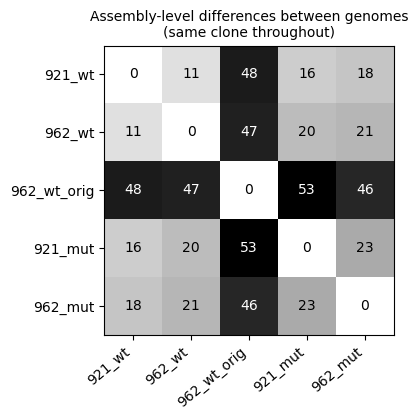

In [9]:
pair = pd.DataFrame(0, index=LABELS, columns=LABELS)
for _, r in AT.iterrows():
    for a in LABELS:
        for b in LABELS:
            pair.loc[a, b] += r[a] != r[b]
fig, ax = plt.subplots(figsize=(5.2, 4.3))
im = ax.imshow(pair.values, cmap="Greys", vmin=0)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, pair.iat[i, j], ha="center", va="center",
                color="white" if pair.iat[i, j] > pair.values.max() / 2 else "black", fontsize=10)
ax.set_xticks(range(5), LABELS, rotation=40, ha="right"); ax.set_yticks(range(5), LABELS)
ax.set_title("Assembly-level differences between genomes\n(same clone throughout)", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "fig_pairwise_differences.png", dpi=200)
pair

## 4. Read-level validation
Assemblies are consensus calls; the reads decide. `map_reads.sh` mapped every read set to the 9-2-1 parent:

| BAM | reads | role |
|---|---|---|
| `921_mut` | SBYK6W_1 ONT | mutant |
| `962_mut` | SBYK6W_2 ONT | mutant |
| `921_wt` | SRR39379361 ONT (the reads behind GCA_059295275.1) | parent |
| `921_wt_illumina` | Φ8 Illumina run 3NKSC3 (host-derived reads) | parent, **non-ONT** check |

There are **no 9-6-2 parent reads**; because 9-6-2 is the same clone, the 9-2-1 parent reads stand in for both
parents. For each site the fraction of reads carrying the non-reference allele (`AF`) is counted; for indels, any
read with an indel of the same type and length within the homopolymer/±5 bp window counts (ONT reads place
homopolymer indels inconsistently).

In [10]:
BAMS = {k: BAM / f"{k}.bam" for k in ["921_wt", "921_wt_illumina", "921_mut", "962_mut"]}
missing = [k for k, p in BAMS.items() if not Path(str(p) + ".bai").exists()]
if missing:
    print("UNDONE — BAMs missing, run map_reads.sh first:", missing)
BAMS = {k: p for k, p in BAMS.items() if k not in missing}
CONTIG = gb.id

flag = []
for k in BAMS:
    txt = (BAM / f"{k}.flagstat.txt").read_text().splitlines()
    tot = int(txt[0].split()[0]); mapped = next(l for l in txt if " mapped (" in l)
    flag.append({"bam": k, "records": tot, "mapped": mapped.split(" mapped")[0].split()[0],
                 "mapped_pct": mapped.split("(")[1].split(":")[0]})
pd.DataFrame(flag)

,bam,records,mapped,mapped_pct
0,921_wt,361276,361225,99.99%
1,921_wt_illumina,19871327,3018225,15.19%
2,921_mut,517592,515960,99.68%
3,962_mut,299212,299052,99.95%


In [11]:
INDEL = re.compile(r"[+-](\d+)")

def parse_bases(s, refbase):
    # samtools mpileup read-base column -> counts
    c = Counter(); i = 0
    while i < len(s):
        ch = s[i]
        if ch == "^": i += 2; continue
        if ch == "$": i += 1; continue
        if ch in "+-":
            m = INDEL.match(s, i); n = int(m.group(1)); seq = s[m.end():m.end() + n].upper()
            c[("ins" if ch == "+" else "del") + seq] += 1; i = m.end() + n; continue
        if ch in ".,": c["REF"] += 1
        elif ch in "*#": c["DELBASE"] += 1
        else: c[ch.upper()] += 1
        i += 1
    return c

def pileup(bam, start1, end1):
    # 1-based inclusive region -> {pos1: (depth, Counter)}
    out = subprocess.run([SAMTOOLS, "mpileup", "-a", "-B", "-Q", "0", "-q", "20", "-d", "0",
                          "-f", str(REF_FA), "-r", f"{CONTIG}:{start1}-{end1}", str(bam)],
                         capture_output=True, text=True, check=True).stdout
    res = {}
    for l in out.splitlines():
        f = l.split("\t")
        res[int(f[1])] = (int(f[3]), parse_bases(f[4], f[2]))
    return res

def allele_af(bam, pos1, allele):
    r, a = parse_allele(allele)
    if len(r) == len(a) == 1:
        d, c = pileup(bam, pos1, pos1)[pos1]
        return d, (c[a] / d if d else np.nan)
    # indel: window = homopolymer run around the site, padded
    hp = hp_run(pos1 - 1)
    lo, hi = pos1 - max(5, hp) - 1, pos1 + max(5, hp) + 1
    pu = pileup(bam, lo, hi)
    key_len = len(r) or len(a); kind = "del" if r else "ins"
    support = sum(n for p, (d, c) in pu.items() for k, n in c.items()
                  if k.startswith(kind) and len(k) - 3 == key_len)
    d = pu.get(pos1, (0, None))[0]
    return d, (min(1.0, support / d) if d else np.nan)

rows = []
for _, s in AT.iterrows():
    for allele in sorted({s[k] for k in LABELS if s[k] != "."}):
        carriers = ",".join(k for k in LABELS if s[k] == allele)
        row = {"pos": s.pos, "allele": allele, "carried_by": carriers}
        for k, bam in BAMS.items():
            d, af = allele_af(bam, s.pos, allele)
            row[f"AF_{k}"] = round(af, 3); row[f"DP_{k}"] = d
        rows.append(row)
RV = pd.DataFrame(rows)
RV

,pos,allele,carried_by,AF_921_wt,DP_921_wt,AF_921_wt_illumina,DP_921_wt_illumina,AF_921_mut,DP_921_mut,AF_962_mut,DP_962_mut
0,161723,G>A,962_wt,0.393,349,0.000,57,0.405,351,0.435,237
1,165683,G>A,962_wt_orig,0.401,352,0.000,78,0.417,367,0.367,215
2,311836,C>T,921_mut,0.374,340,0.000,122,0.418,510,0.377,239
3,311837,T>C,921_mut,0.274,340,0.000,119,0.316,510,0.305,239
4,341676,insA,962_wt_orig,0.052,403,0.000,109,0.039,568,0.030,302
5,446686,insC,962_wt_orig,0.046,304,0.000,120,0.109,339,0.063,223
6,542713,C>T,962_wt_orig,0.445,290,0.000,72,0.503,334,0.376,242
7,724895,C>T,962_wt_orig,0.331,317,0.000,97,0.296,406,0.331,239
8,1005661,insT,962_wt_orig,0.006,313,0.000,61,0.044,386,0.056,234
9,1005662,C>T,962_mut,0.476,313,0.000,59,0.409,386,0.421,233


### 4b. Verdict per site
Thresholds (ONT, ≥100× here): an allele is **present** in a sample if AF ≥ 0.7, **absent** if AF ≤ 0.2, otherwise
**mixed** (systematic error, or a sub-population). For each lineage:

The ONT parent reads are the like-for-like baseline (same chemistry → same systematic errors); the Illumina parent
reads say what the parent base really is.

- `real mutation` — present in the mutant reads, absent in the parent ONT reads, and absent in the Illumina parent reads.
- `parent assembly error` — the Illumina parent reads carry the allele (≥ 0.7): the parent *assembly* was wrong and
  nothing changed.
- `ONT systematic error` — the allele sits at an intermediate AF in **every** ONT read set (mutant AF within 0.25 of
  parent ONT AF) and is absent in Illumina. Each assembler run picks one side of a ~50/50 basecalling split, which is
  why these sites flip between assemblies of the same clone.
- `no change in reads` — absent from both mutant and parent reads (an assembly-only call).
- `ambiguous` — anything else (e.g. mutant AF clearly above parent but below 0.7: possible mixed culture).

In [12]:
PRES, ABS = 0.7, 0.2
def state(af):
    if pd.isna(af): return "n/a"
    return "present" if af >= PRES else ("absent" if af <= ABS else "mixed")

def verdict(row, mut):
    m_af, p_af = row[f"AF_{mut}"], row.get("AF_921_wt", np.nan)
    m, p, il = state(m_af), state(p_af), state(row.get("AF_921_wt_illumina", np.nan))
    if il == "present":                                              return "parent assembly error"
    if m == "present" and p == "absent" and il in ("absent", "n/a"): return "real mutation"
    if m == "absent" and p == "absent":                               return "no change in reads"
    if abs(m_af - p_af) < 0.25 and il in ("absent", "n/a"):           return "ONT systematic error"
    return "ambiguous"

for mut in ["921_mut", "962_mut"]:
    RV[f"verdict_{mut}"] = RV.apply(verdict, axis=1, mut=mut) if f"AF_{mut}" in RV else "UNDONE"
RV = RV.merge(AT[["pos", "lineage_change", "site_class", "homopolymer", "locus", "gene", "product", "effect", "aa_change"]],
              on="pos", how="left")
RV.to_csv(OUT / "read_validation_sites.tsv", sep="\t", index=False)
for mut in ["921_mut", "962_mut"]:
    print(mut, RV[f"verdict_{mut}"].value_counts().to_dict())

921_mut {'no change in reads': 32, 'ONT systematic error': 29, 'parent assembly error': 9}
962_mut {'ONT systematic error': 30, 'no change in reads': 30, 'parent assembly error': 9, 'real mutation': 1}


### 4c. Genome-wide read scan — mutations the assemblies might have hidden
An assembly is one consensus; a mutation can be missed if it sits in a repeat, or if the culture was mixed and the
consensus went with the majority. So every position of each mutant pileup is scanned for a non-reference allele at
AF ≥ 0.3 (depth ≥ 30), then the same position is checked in the parent reads. Results are cached in
`genome_scan_<mut>.tsv` (the full pileup takes several minutes per sample).

In [13]:
SCAN_AF, SCAN_DP = 0.30, 30

def scan(bam, cache):
    if cache.exists():
        return pd.read_csv(cache, sep="\t")
    p = subprocess.Popen([SAMTOOLS, "mpileup", "-B", "-Q", "0", "-q", "20", "-d", "0", "-f", str(REF_FA), str(bam)],
                         stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True, bufsize=1 << 20)
    hits = []
    for l in p.stdout:
        f = l.split("\t", 5); d = int(f[3])
        if d < SCAN_DP: continue
        b = f[4]
        # cheap pre-filter: enough non-reference characters to possibly reach SCAN_AF
        if (len(b) - b.count(".") - b.count(",")) < SCAN_AF * d: continue
        c = parse_bases(b, f[2])
        for k, n in c.items():
            if k in ("REF", "DELBASE"): continue
            if n / d >= SCAN_AF:
                hits.append({"pos": int(f[1]), "ref": f[2], "alt": k, "depth": d, "AF": round(n / d, 3)})
    p.wait()
    df = pd.DataFrame(hits, columns=["pos", "ref", "alt", "depth", "AF"])
    df.to_csv(cache, sep="\t", index=False)
    return df

SCAN = {}
for k in ["921_wt", "921_mut", "962_mut"]:
    if k in BAMS:
        SCAN[k] = scan(BAMS[k], OUT / f"genome_scan_{k}.tsv")
        print(f"{k:8s} {len(SCAN[k]):6d} positions with a non-reference allele at AF >= {SCAN_AF}")

921_wt      132 positions with a non-reference allele at AF >= 0.3
921_mut     144 positions with a non-reference allele at AF >= 0.3
962_mut     149 positions with a non-reference allele at AF >= 0.3


Most of those positions are ONT systematic errors that show up in **every** ONT sample. A position is kept as
mutant-specific only if the parent ONT reads did **not** pass the same scan for the same allele, and its exact parent
AF (re-counted) is ≤ 0.10. Mpileup reports an indel on the base *before* it, so indel positions are shifted by one
to annotate the affected base.

In [14]:
PARENT_MAX = 0.10
def pos0_of(pos1, alt):
    return pos1 if alt.startswith(("ins", "del")) else pos1 - 1

def scan_allele(ref, alt):
    return alt if alt.startswith(("ins", "del")) else f"{ref}>{alt}"

par_keys = set(zip(SCAN["921_wt"].pos, SCAN["921_wt"].alt)) if "921_wt" in SCAN else set()
at_pos = np.array(sorted(AT.pos))
scan_rows = []
for mut in ["921_mut", "962_mut"]:
    if mut not in SCAN: continue
    other = SCAN.get("962_mut" if mut == "921_mut" else "921_mut")
    okeys = set(zip(other.pos, other.alt)) if other is not None else set()
    for _, h in SCAN[mut].iterrows():
        if (h.pos, h.alt) in par_keys: continue
        row = {"mutant": mut, **h.to_dict(), "also_in_other_mutant": (h.pos, h.alt) in okeys}
        for k in ["921_wt", "921_wt_illumina"]:
            if k in BAMS:
                d, c = pileup(BAMS[k], int(h.pos), int(h.pos))[int(h.pos)]
                row[f"AF_{k}"] = round(c[h.alt] / d, 3) if d else np.nan; row[f"DP_{k}"] = d
        scan_rows.append(row)
SC = pd.DataFrame(scan_rows)
if len(SC):
    SC["parent_clean"] = SC["AF_921_wt"] <= PARENT_MAX
    SC["verdict"] = np.where(SC.parent_clean & (SC.AF >= PRES) & (SC.get("AF_921_wt_illumina", 0) <= ABS), "real mutation",
                    np.where(SC.parent_clean, "low-AF read-only call", "ONT systematic error"))
    SC["in_assembly_table"] = [bool(len(at_pos)) and np.abs(at_pos - p).min() <= 10 for p in SC.pos]
    ann = SC.apply(lambda r: pd.Series(effect(pos0_of(int(r.pos), r.alt), scan_allele(r.ref, r.alt)))[
        ["locus", "gene", "product", "effect", "aa_change"]], axis=1)
    SC = pd.concat([SC.reset_index(drop=True), ann.reset_index(drop=True)], axis=1)
    SC.to_csv(OUT / "genome_scan_annotated.tsv", sep="\t", index=False)
    display(SC[SC.parent_clean].sort_values(["mutant", "AF"], ascending=[True, False]))
else:
    print("no mutant-specific read-scan positions")

,mutant,pos,ref,alt,depth,AF,also_in_other_mutant,AF_921_wt,DP_921_wt,AF_921_wt_illumina,DP_921_wt_illumina,parent_clean,verdict,in_assembly_table,locus,gene,product,effect,aa_change
12,921_mut,2265430,G,A,181,0.331,True,0.100,80,0.0,105,True,low-AF read-only call,True,OHPLIO_02049,,hypothetical protein,synonymous,
5,921_mut,782104,G,A,390,0.315,False,0.067,314,0.0,98,True,low-AF read-only call,False,OHPLIO_00709,pth,aminoacyl-tRNA hydrolase,missense,S75F (of 194)
72,962_mut,4643730,T,C,264,0.996,False,0.000,181,0.0,60,True,real mutation,True,OHPLIO_04215,,"Stealth protein CR3, conserved region 3",missense,F126L (of 490)
51,962_mut,2265430,G,A,144,0.340,True,0.100,80,0.0,105,True,low-AF read-only call,True,OHPLIO_02049,,hypothetical protein,synonymous,
65,962_mut,3777719,C,T,261,0.303,False,0.090,335,0.0,49,True,low-AF read-only call,False,OHPLIO_03401,caiA,Acyl-CoA dehydrogenase,missense,D262N (of 386)
62,962_mut,3521037,G,A,258,0.302,False,0.097,329,0.0,57,True,low-AF read-only call,False,OHPLIO_03157,lysR,HTH lysR-type domain-containing protein,missense,D10N (of 304)


### 4d. Read support at every assembly-level site
Each row is one site/allele; columns are read sets. A real lineage mutation looks like a dark cell in its mutant column
and a white cell in every parent column. Systematic ONT errors look like the same grey in every ONT column.

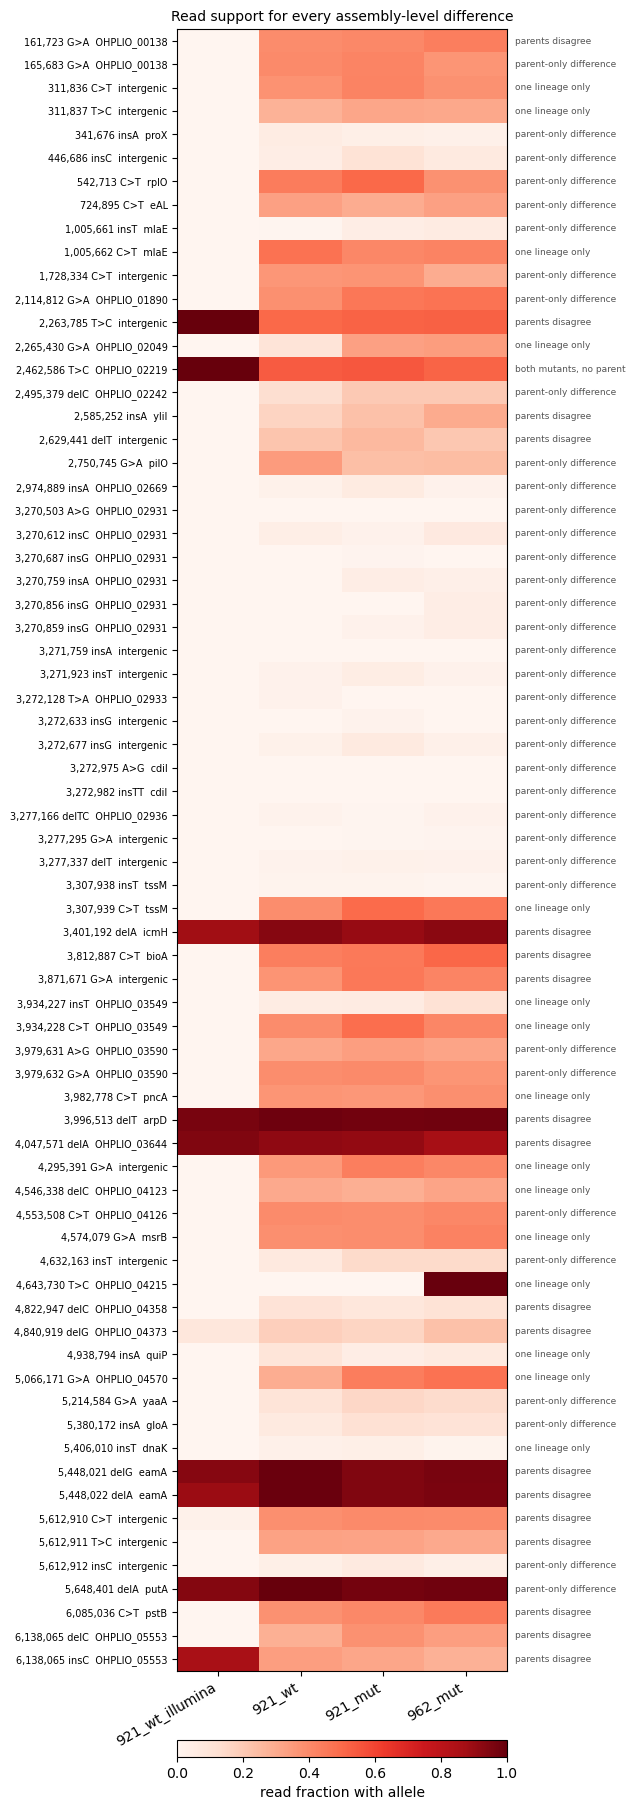

In [15]:
afc = [c for c in ["AF_921_wt_illumina", "AF_921_wt", "AF_921_mut", "AF_962_mut"] if c in RV]
H = RV.sort_values("pos")
lab = [f"{p:,} {al[:12]}  {(g or l or 'intergenic')}" for p, al, g, l in zip(H.pos, H.allele, H.gene.fillna(""), H.locus.fillna(""))]
fig, ax = plt.subplots(figsize=(6.5, 0.24 * len(H) + 1.5))
im = ax.imshow(H[afc].astype(float).values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(afc)), [c[3:] for c in afc], rotation=30, ha="right")
ax.set_yticks(range(len(H)), lab, fontsize=7)
for i, cls in enumerate(H.site_class):
    ax.text(len(afc) - 0.4, i, cls, fontsize=6.5, va="center", color="#555")
plt.colorbar(im, ax=ax, orientation="horizontal", fraction=0.015, pad=0.04, label="read fraction with allele")
ax.set_title("Read support for every assembly-level difference", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "fig_read_support_heatmap.png", dpi=200, bbox_inches="tight")

## 5. Gene content — did any protein change?
Exact protein sequences from each Bakta `.faa` are compared between parent and mutant of each lineage. A protein
that differs must be explained by one of the sites above (frameshift / missense); anything else would mean a gene
gain or loss.

In [16]:
def prot_set(k):
    return {str(r.seq).rstrip("*"): r.description.split(" ", 1)[1] for r in SeqIO.parse(FILES[k]["faa"], "fasta")}

gc_rows = []
for lin, (wt, mut) in LINEAGES.items():
    pw, pm = prot_set(wt), prot_set(mut)
    only_w = {s: d for s, d in pw.items() if s not in pm}; only_m = {s: d for s, d in pm.items() if s not in pw}
    gc_rows.append({"lineage": lin, "proteins_parent": len(pw), "proteins_mutant": len(pm),
                    "parent_only": len(only_w), "mutant_only": len(only_m),
                    "parent_only_products": "; ".join(sorted(only_w.values()))[:400],
                    "mutant_only_products": "; ".join(sorted(only_m.values()))[:400]})
pd.DataFrame(gc_rows)

,lineage,proteins_parent,proteins_mutant,parent_only,mutant_only,parent_only_products,mutant_only_products
0,921,5442,5445,8,11,Acyl-homoserine lactone acylase QuiP; EamA domain-containing prote...,Acyl-homoserine lactone acylase QuiP; Glucose/arabinose dehydrogen...
1,962,5441,5444,12,15,Alkaline protease secretion transporter ATP-binding protein; CBASS...,Alkaline protease secretion transporter ATP-binding protein; CBASS...


**Reading.** None of these protein differences is supported by reads except Stealth CR3 (§4): they come from
assembly-only indels (frameshifted ORFs split or merged — compare §4b) and from Bakta choosing a different start codon
on identical DNA (e.g. the O-antigen SDR oxidoreductase, 303 vs 321 aa in `962_wt`). No gene was gained or lost.

## 6. Polysaccharide cassettes
Three loci, bounded on the 9-2-1 parent by their flanking genes:

| locus | 9-2-1 span | bounded by | source |
|---|---|---|---|
| **O-antigen** (OSA) | 1,409,400–1,435,896 (23 genes) | ihfB → LPS assembly protein A → MBL hydrolase ‖ beta-ketoacyl synthase | `code/0727_o_antigen_comparison/` (`locus_bounds.tsv`) |
| **LPS core** (*waa*) | 396,272–403,232 (7 genes, `OHPLIO_00331–00337`) | glnE ‖ dermonecrotic-toxin-domain protein | this notebook, from annotation |
| **Capsule-type cluster** | 4,638,582–4,668,332 (23 genes, `OHPLIO_04210–04232`) | kdsA ‖ aceK | this notebook, from annotation |

The capsule-type cluster starts with an ABC export system (permease + ATP-binding protein + outer-membrane
polysaccharide export protein — the Wzm/Wzt + Wza-like layout of ABC-dependent capsules) followed by sugar /
glycerol-phosphate enzymes (Stealth CR3, TagD, CDP-glycerol glycerophosphotransferase, CapA, XcbB/CpsF). It is
called “capsule-type” because that is what the annotation supports; no capsule has been observed in these cells.

In [17]:
OAG = pd.read_csv(ROOT / "code/output/0727_o_antigen_comparison/locus_bounds.tsv", sep="\t").set_index("isolate")
CASSETTES = {
    "O-antigen":     (int(OAG.loc["9-2-1", "start_bp"]), int(OAG.loc["9-2-1", "end_bp"]), "#16a085"),
    "LPS core (waa)": (396272, 403232, "#b7950b"),
    "Capsule-type":  (4638582, 4668332, "#7d3c98"),
}
C_REAL, C_AMB, C_ART, C_START = "#c0392b", "#f39c12", "#b3b6b7", "#5dade2"

def lineage_sites(mut):
    # sites where the lineage changed at assembly level, plus read-scan hits, with their verdict
    lin = mut.split("_")[0]
    v = RV[RV.lineage_change.str.contains(lin)].copy()
    v["verdict"] = v[f"verdict_{mut}"] if f"verdict_{mut}" in v else "UNDONE"
    v = v[v.carried_by.str.contains(mut) | v.carried_by.str.contains(LINEAGES[lin][0])]
    return v

for name, (s, e, _) in CASSETTES.items():
    hits = AT[(AT.pos >= s) & (AT.pos <= e)]
    sc = SC[(SC.pos >= s) & (SC.pos <= e)] if len(SC) else SC
    genes = CDS[(CDS.start >= s - 1) & (CDS.end <= e)]
    print(f"{name:15s} {s:>9,}-{e:>9,}  {len(genes):2d} CDS  assembly diffs: {len(hits)}  read-scan hits: {len(sc)}")

O-antigen       1,409,400-1,435,896  23 CDS  assembly diffs: 0  read-scan hits: 0
LPS core (waa)    396,272-  403,232   7 CDS  assembly diffs: 0  read-scan hits: 0
Capsule-type    4,638,582-4,668,332  23 CDS  assembly diffs: 1  read-scan hits: 1


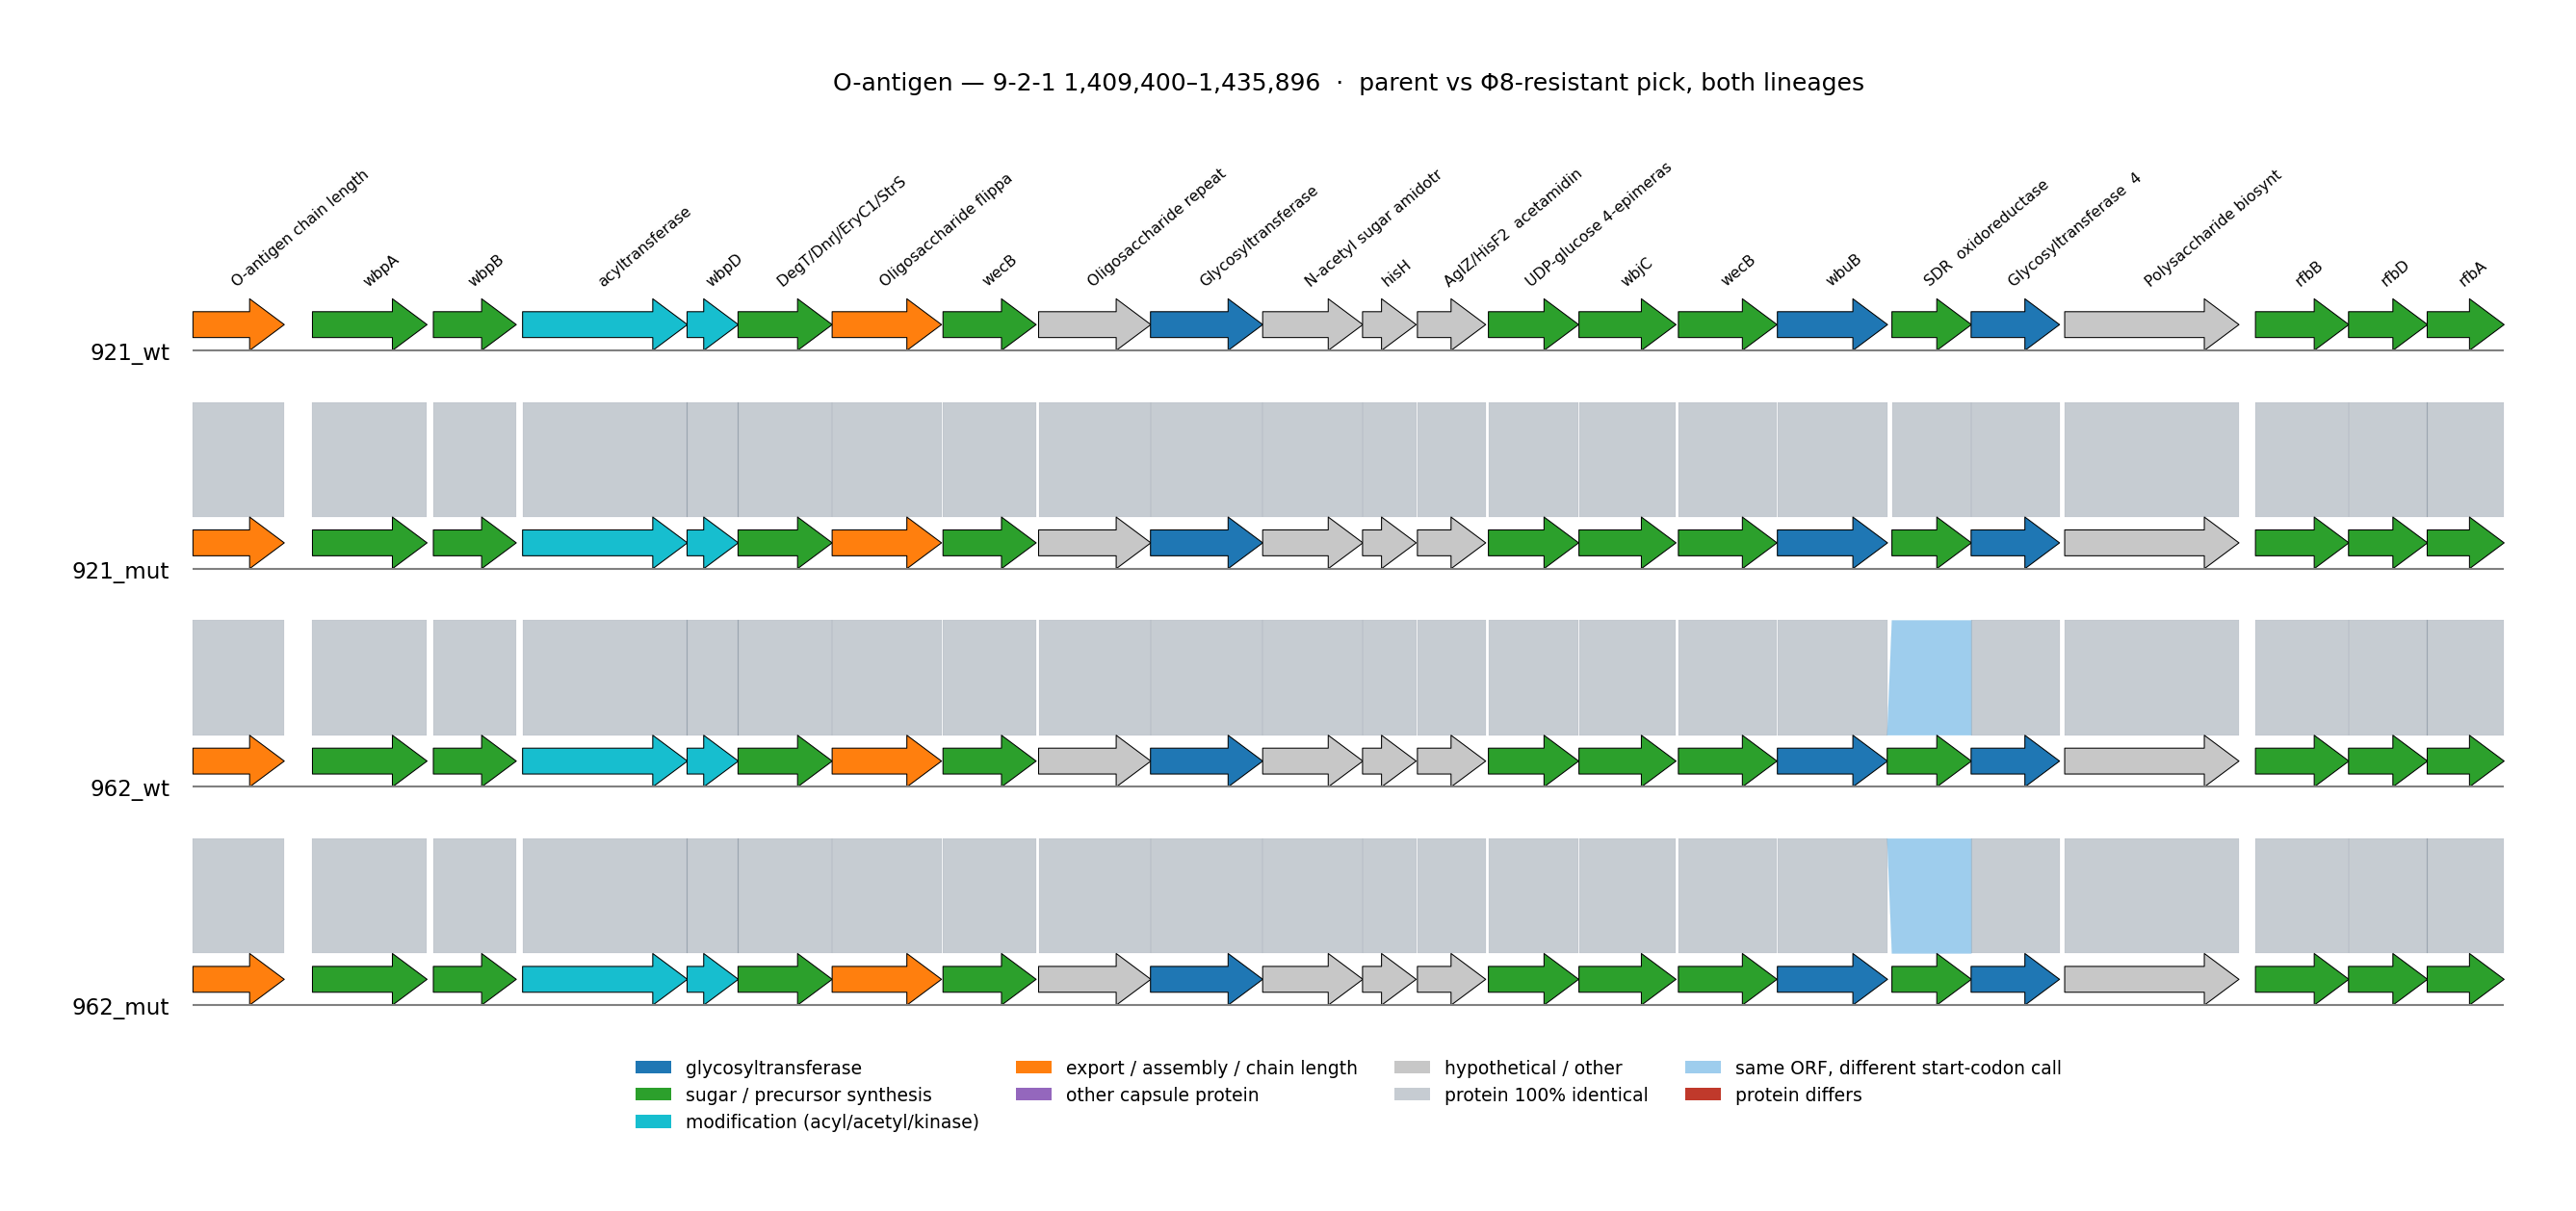

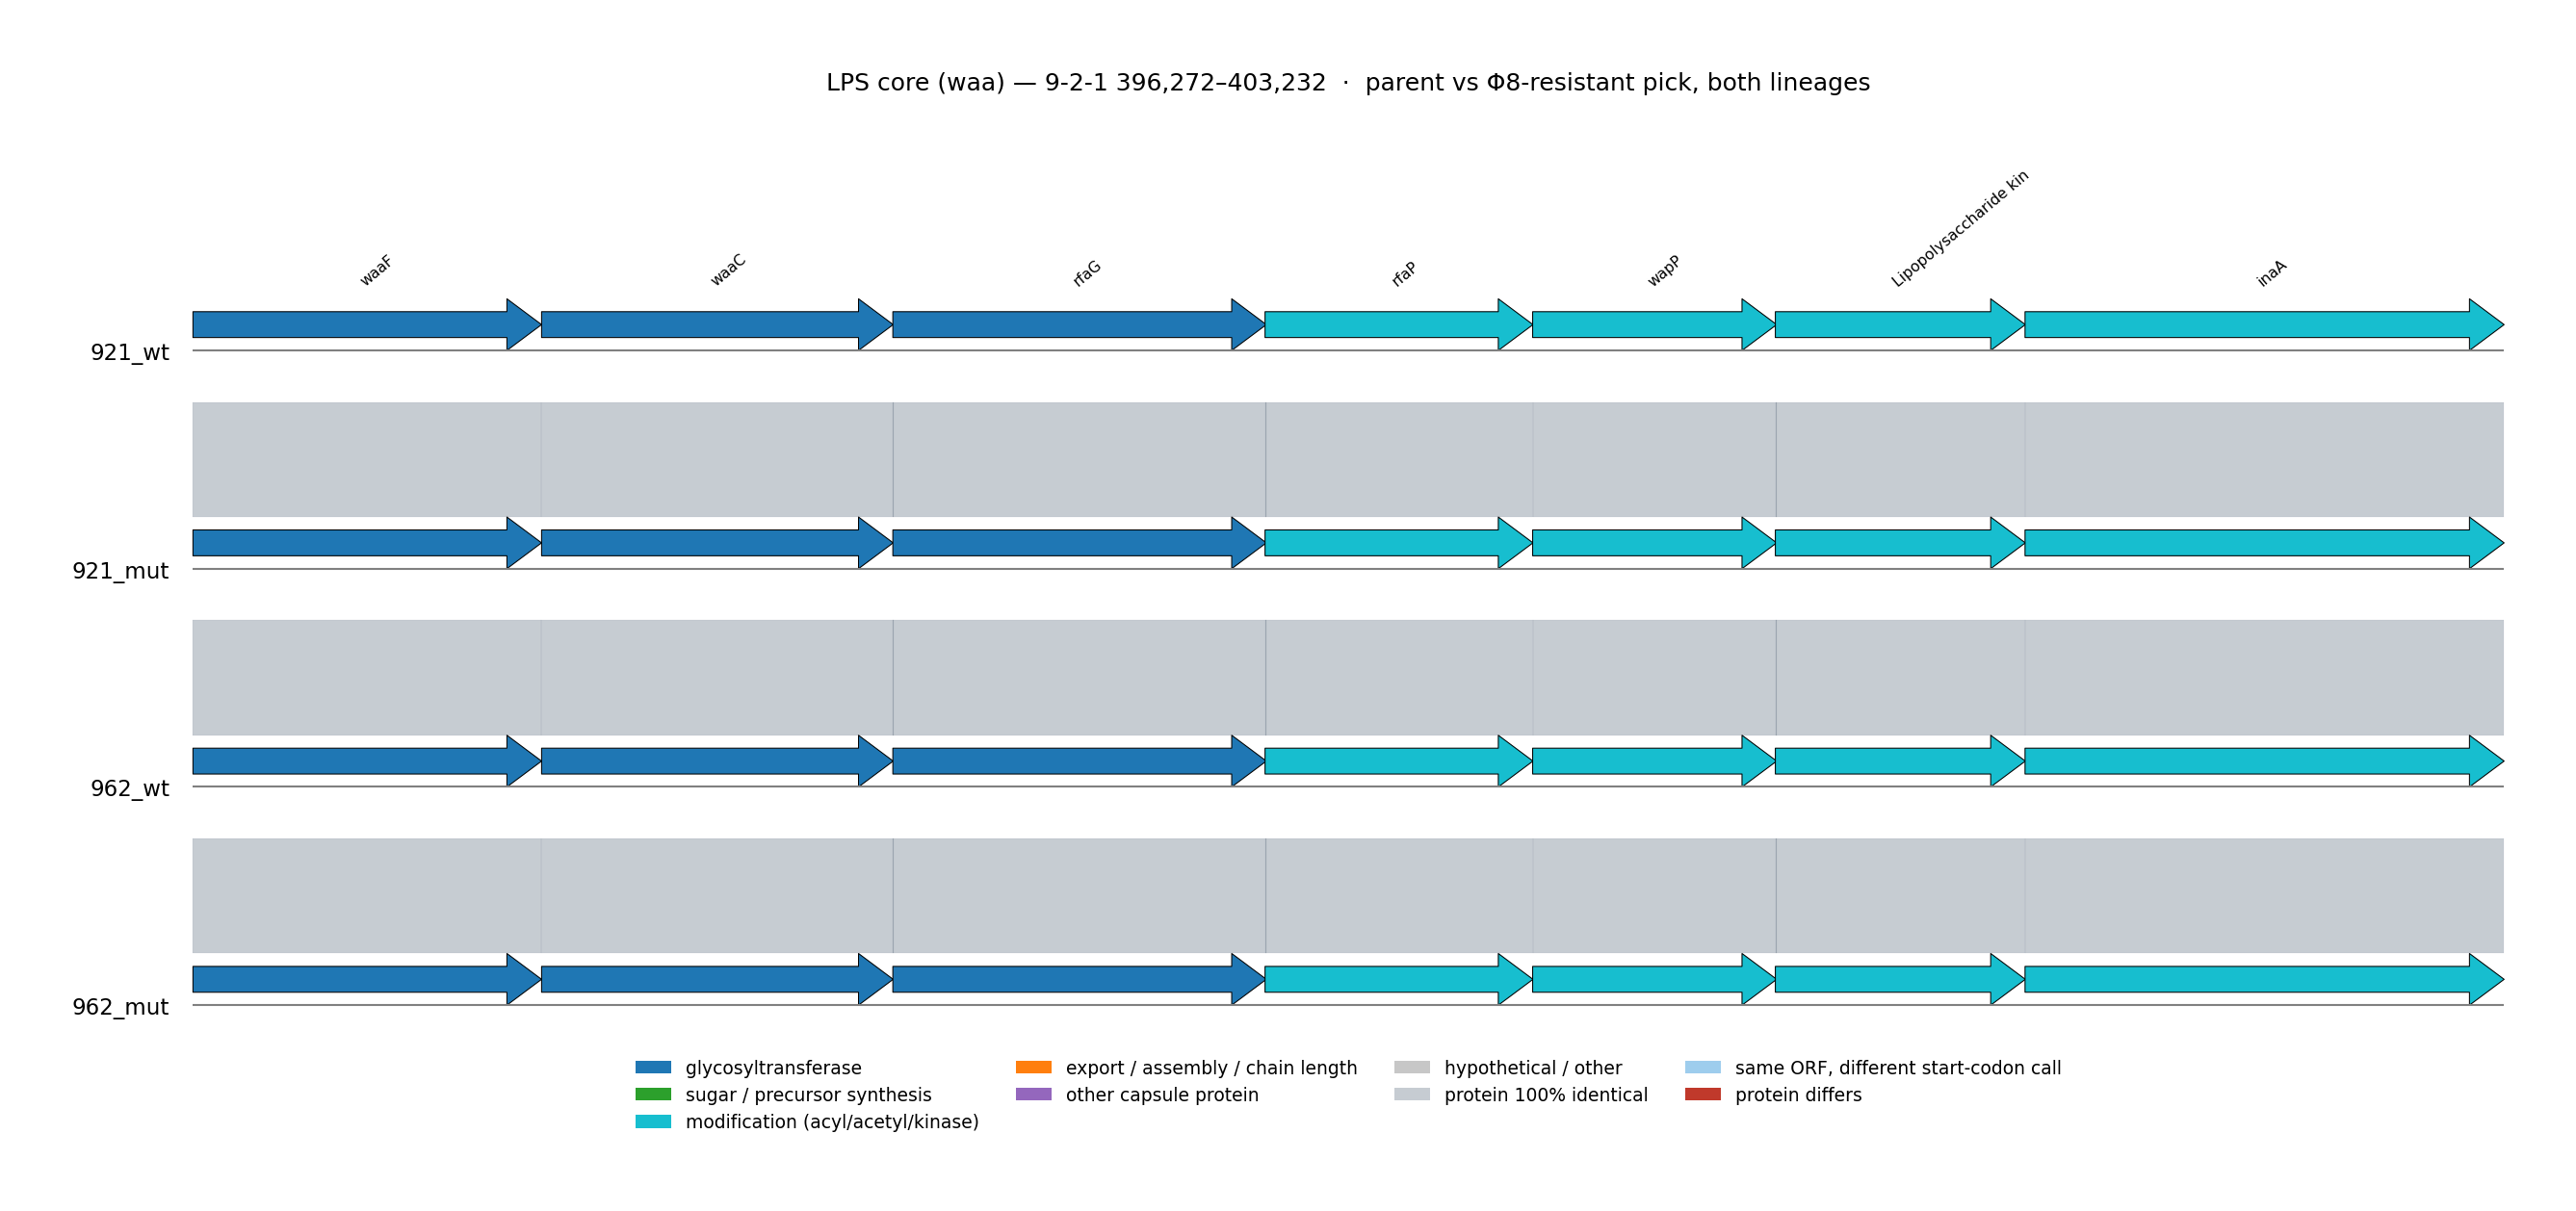

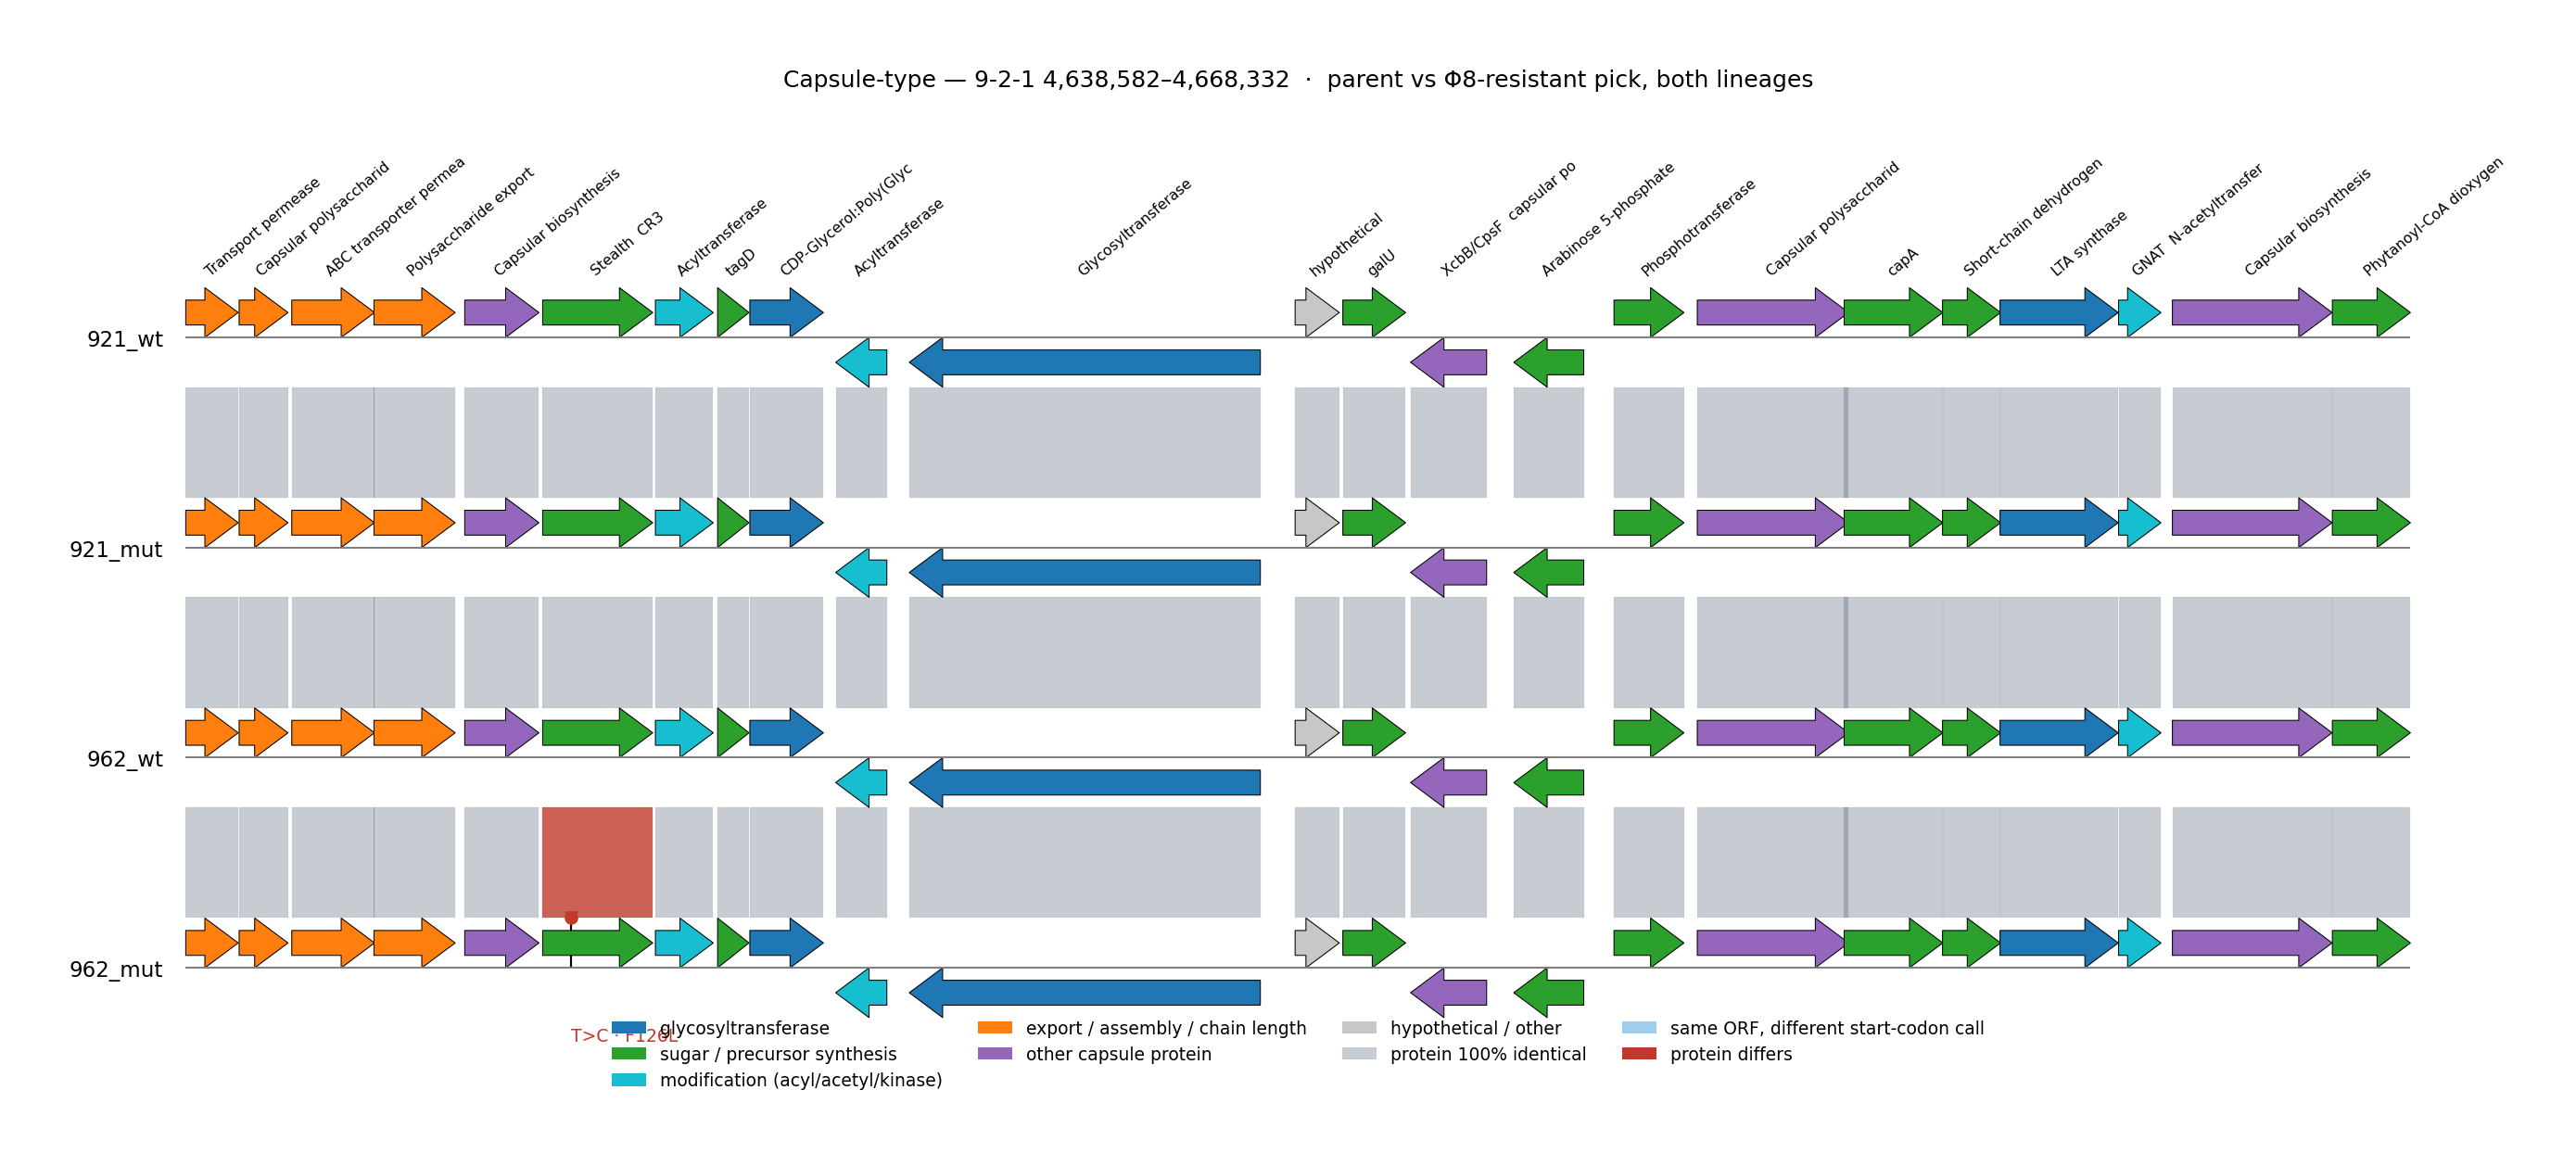

In [18]:
from pygenomeviz import GenomeViz
from pygenomeviz.parser import Genbank as PGVGenbank
from matplotlib.patches import Patch
from Bio.Align import PairwiseAligner

FUNC = [  # (class, regex on product/gene, color) — first match wins
    ("glycosyltransferase", r"glycosyl|Glycosyltransferase|heptosyltransferase|RfaG|glycerophosphotransferase|LTA synthase", "#1f77b4"),
    ("sugar / precursor synthesis", r"dehydratase|epimerase|reductase|dehydrogenase|isomerase|thymidylyltransferase|uridylyltransferase|cytidylyltransferase|aminotransferase|oxidase|wbp|rfb|galU|kdsA|tagD|Stealth|CapA|Phosphotransferase|Phytanoyl", "#2ca02c"),
    ("modification (acyl/acetyl/kinase)", r"acyltransferase|Acyltransferase|acetyltransferase|kinase|Kinase|WapP|RfaP|InaA", "#17becf"),
    ("export / assembly / chain length", r"transport|permease|export|flippase|ATP-binding|chain length|ligase|Wz|assembly protein", "#ff7f0e"),
    ("other capsule protein", r"[Cc]apsul|XcbB|CpsF", "#9467bd"),
]
def fclass(prod):
    for n, rx, c in FUNC:
        if re.search(rx, prod or ""): return n, c
    return "hypothetical / other", "#c7c7c7"

PGV = {k: PGVGenbank(FILES[k]["gbff"]) for k in ["921_wt", "921_mut", "962_wt", "962_mut"]}

def locate(k, s, e, flank=60):
    # map a 9-2-1 span onto assembly k by exact search of its boundary sequences
    a = SEQ[k].find(REF_SEQ[s - 1:s - 1 + flank]); b = SEQ[k].find(REF_SEQ[e - flank:e])
    assert a >= 0 and b >= 0, (k, s, e)
    return a + 1, b + flank

aligner = PairwiseAligner(mode="global", open_gap_score=-10, extend_gap_score=-0.5)
def pid(a, b):
    if a == b: return 100.0
    al = aligner.align(a, b)[0]
    return 100 * sum(x == y for x, y in zip(*al)) / max(len(a), len(b))

def cassette_fig(name, s, e):
    tracks = ["921_wt", "921_mut", "962_wt", "962_mut"]
    gv = GenomeViz(fig_width=16, fig_track_height=0.75, feature_track_ratio=0.45, link_track_ratio=0.5)
    feats = {}
    for k in tracks:
        a, b = locate(k, s, e)
        fs = [f for f in PGV[k].extract_features("CDS", target_range=(a - 1, b))]
        feats[k] = fs
        tr = gv.add_feature_track(f"{k}", (a - 1, b), labelsize=11)
        seg = tr.segments[0]
        for f in fs:
            prod = f.qualifiers.get("product", [""])[0]; gene = f.qualifiers.get("gene", [""])[0]
            seg.add_features(f, fc=fclass(prod)[1], lw=0.5, label_type=None)
            if tracks.index(k) == 0:
                short = gene or re.sub(r"(protein|domain-containing|family|conserved region \d+|,)", "", prod).strip()[:22]
                seg.add_text((int(f.location.start) + int(f.location.end)) / 2, short, size=7.5, rotation=40)
        # mark lineage-changed sites inside the window (assembly + read scan), on the mutant track
        if k.endswith("_mut"):
            off = a - s
            for _, r in lineage_sites(k).iterrows():
                if s <= r.pos <= e:
                    c = {"real mutation": C_REAL, "ambiguous": C_AMB}.get(r.verdict, C_ART)
                    seg.add_lollipop(r.pos + off, point_kws={"color": c})
                    if r.verdict == "real mutation":
                        seg.add_text(r.pos + off, f"{r.allele} · {r.aa_change.split(' ')[0]}", size=9, rotation=0,
                                     vpos="bottom", color=C_REAL)
            if k in SCAN and len(SC):
                for _, r in SC[(SC.mutant == k) & SC.parent_clean & (SC.pos >= s) & (SC.pos <= e)].iterrows():
                    seg.add_lollipop(r.pos + off, point_kws={"color": C_REAL, "marker": "v"})
    def rel(f, k): return int(f.location.start) - locate(k, s, e)[0]
    for t1, t2 in [("921_wt", "921_mut"), ("921_mut", "962_wt"), ("962_wt", "962_mut")]:
        for f1 in feats[t1]:
            f2 = min(feats[t2], key=lambda f: abs(rel(f, t2) - rel(f1, t1)) + (1e9 if f.location.strand != f1.location.strand else 0))
            p1 = str(f1.qualifiers.get("translation", [""])[0]); p2 = str(f2.qualifiers.get("translation", [""])[0])
            # same protein with a different start-codon call (one is an N-terminal extension of the other) is an
            # annotation difference, not a sequence change
            if p1 == p2:                               col, al = "#5d6d7e", 0.35
            elif p1.endswith(p2) or p2.endswith(p1):   col, al = C_START, 0.6
            else:                                      col, al = C_REAL, 0.8
            gv.add_link((t1, int(f1.location.start), int(f1.location.end)),
                        (t2, int(f2.location.start), int(f2.location.end)), color=col, alpha=al)
    fig = gv.plotfig(dpi=150)
    hs = [Patch(fc=c, label=n) for n, _, c in FUNC] + [Patch(fc="#c7c7c7", label="hypothetical / other"),
          Patch(fc="#5d6d7e", alpha=0.35, label="protein 100% identical"),
          Patch(fc=C_START, alpha=0.6, label="same ORF, different start-codon call"), Patch(fc=C_REAL, label="protein differs")]
    fig.legend(handles=hs, loc="lower center", ncols=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle(f"{name} — 9-2-1 {s:,}–{e:,}  ·  parent vs Φ8-resistant pick, both lineages", fontsize=12, y=1.30)
    stem = re.sub(r"\W+", "_", name.lower()).strip("_")
    fig.savefig(OUT / f"fig_cassette_{stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(OUT / f"fig_cassette_{stem}.svg", bbox_inches="tight")
    return fig

for name, (s, e, _) in CASSETTES.items():
    display(cassette_fig(name, s, e)); plt.close("all")

## 7. Circular genome map
9-2-1 parent coordinates. Outer → inner: polysaccharide cassettes · lineage-changed sites for `921_mut` and
`962_mut`, coloured by read verdict (red = real mutation, orange = ambiguous, grey = artifact / no change) · CDS
forward / reverse · GC content (deviation from mean) · GC skew. Real and ambiguous sites are labelled with their gene.

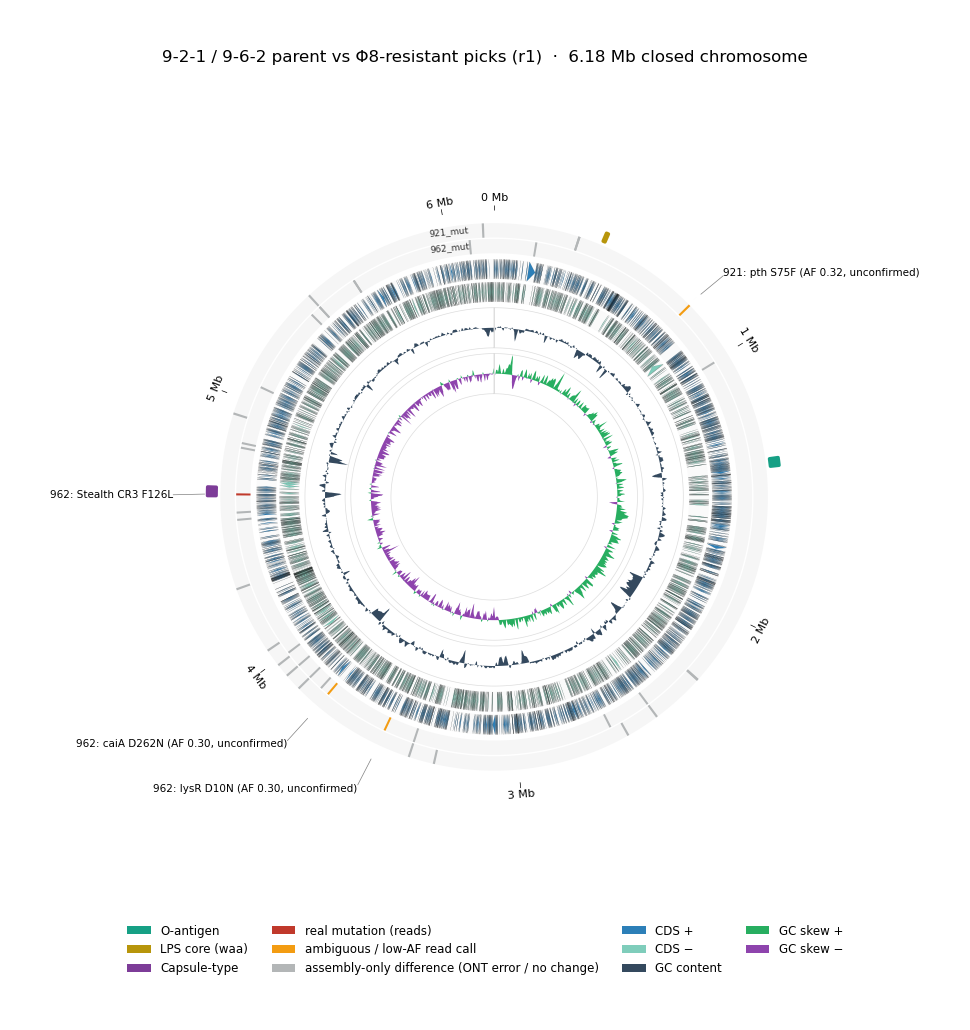

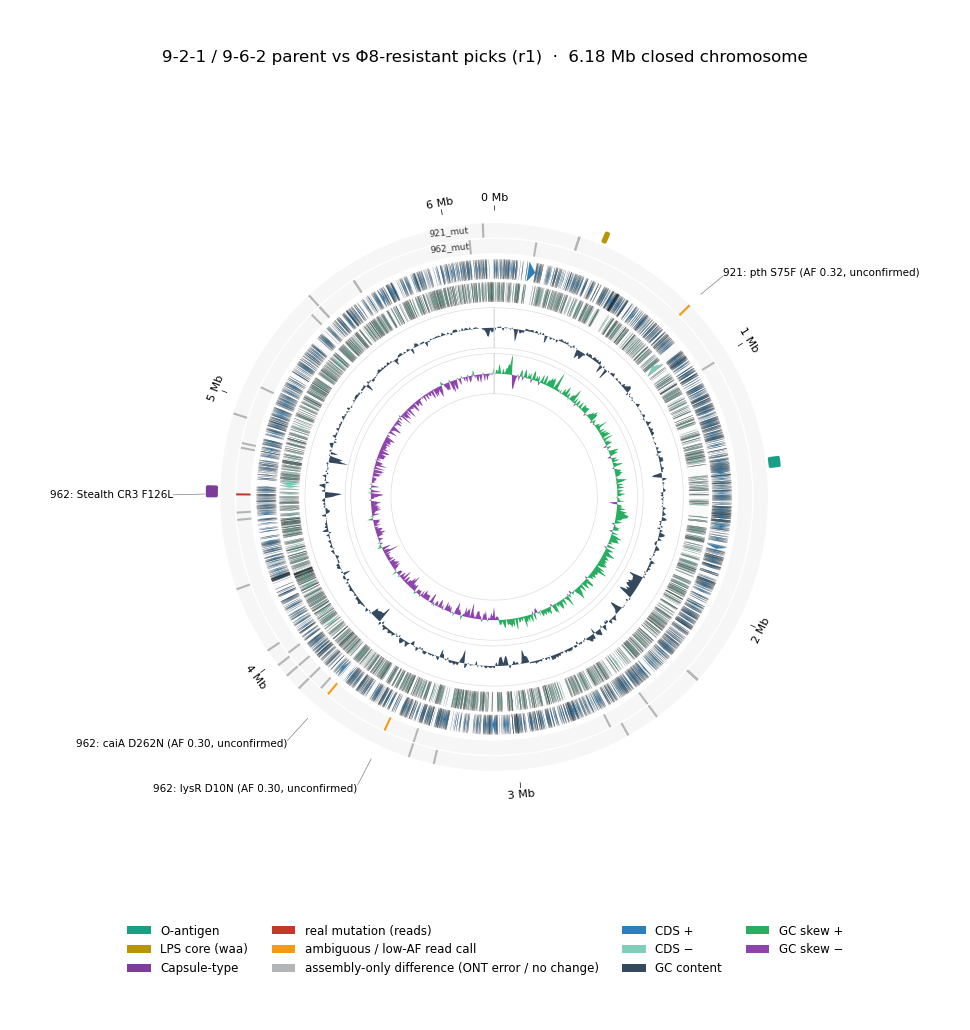

In [19]:
from pycirclize import Circos
from pycirclize.parser import Genbank

gbk = Genbank(FILES[REF]["gbff"])
circos = Circos(sectors={gbk.name: gbk.range_size})
sec = circos.sectors[0]

cas = sec.add_track((97, 100)); cas.axis(fc="none", ec="none")
for name, (s, e, c) in CASSETTES.items():
    cas.rect(s - 1, e, fc=c, ec=c, lw=2.5)

def short_name(gene, product):
    return gene or re.sub(r"\s+", " ", re.sub(r"(protein|domain-containing|family|conserved region \d+|,)", "", product or "")).strip()[:20]

def vcolor(v):
    return {"real mutation": C_REAL, "ambiguous": C_AMB, "low-AF read-only call": C_AMB}.get(v, C_ART)

labels = []
for (lo, hi), mut in [((90.5, 95.5), "921_mut"), ((85, 90), "962_mut")]:
    t = sec.add_track((lo, hi)); t.axis(fc="#f6f6f6", ec="none")
    v = lineage_sites(mut)
    for _, r in v.iterrows():
        t.rect(r.pos - 1 - 4000, r.pos - 1 + 4000, fc=vcolor(r.verdict), ec="none")
        if r.verdict in ("real mutation", "ambiguous"):
            lab = short_name(r.gene, r["product"]) if r.locus else "intergenic"
            labels.append((r.pos, f"{mut.split('_')[0]}: {lab} {r.aa_change.split(' ')[0]}"))
    if len(SC):
        for _, r in SC[(SC.mutant == mut) & SC.parent_clean & ~SC.in_assembly_table].iterrows():
            t.rect(r.pos - 1 - 4000, r.pos - 1 + 4000, fc=vcolor(r.verdict), ec="none")
            labels.append((int(r.pos), f"{mut.split('_')[0]}: {short_name(r.gene, r['product'])} {r.aa_change.split(' ')[0]} (AF {r.AF:.2f}, unconfirmed)"))
    t.text(mut, x=gbk.range_size * 0.985, r=(lo + hi) / 2, size=6.5, color="#333", ha="right")

f = sec.add_track((76, 83), r_pad_ratio=0.02); f.axis(fc="#fafafa", ec="none")
f.genomic_features(gbk.extract_features("CDS", target_strand=1), plotstyle="arrow", fc="#2c7fb8", lw=0.05)
r_ = sec.add_track((68, 75), r_pad_ratio=0.02); r_.axis(fc="#fafafa", ec="none")
r_.genomic_features(gbk.extract_features("CDS", target_strand=-1), plotstyle="arrow", fc="#7fcdbb", lw=0.05)
pos, gcv = gbk.calc_gc_content(window_size=10000, step_size=5000); gcv = gcv - gbk.calc_genome_gc_content()
g = sec.add_track((52, 66)); g.axis(fc="none", ec="#dddddd")
lim = float(abs(gcv).max()); g.fill_between(pos, gcv, 0, vmin=-lim, vmax=lim, fc="#34495e", lw=0.1)
pos, sk = gbk.calc_gc_skew(window_size=10000, step_size=5000)
k_ = sec.add_track((36, 50)); k_.axis(fc="none", ec="#dddddd"); lim = float(abs(sk).max())
k_.fill_between(pos, np.clip(sk, 0, None), 0, vmin=-lim, vmax=lim, fc="#27ae60", lw=0.1)
k_.fill_between(pos, np.clip(sk, None, 0), 0, vmin=-lim, vmax=lim, fc="#8e44ad", lw=0.1)
cas.xticks_by_interval(1_000_000, outer=True, label_size=8, label_formatter=lambda v: f"{v / 1e6:.0f} Mb")
for p, txt in labels:
    cas.annotate(p - 1, txt, label_size=7.5, min_r=101, max_r=112, shorten=None)

fig = circos.plotfig(figsize=(9, 9))
hs = [Patch(fc=c, label=n) for n, (_, _, c) in CASSETTES.items()] + [
      Patch(fc=C_REAL, label="real mutation (reads)"), Patch(fc=C_AMB, label="ambiguous / low-AF read call"),
      Patch(fc=C_ART, label="assembly-only difference (ONT error / no change)"),
      Patch(fc="#2c7fb8", label="CDS +"), Patch(fc="#7fcdbb", label="CDS −"),
      Patch(fc="#34495e", label="GC content"), Patch(fc="#27ae60", label="GC skew +"), Patch(fc="#8e44ad", label="GC skew −")]
fig.legend(handles=hs, loc="lower center", ncols=4, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("9-2-1 / 9-6-2 parent vs Φ8-resistant picks (r1)  ·  6.18 Mb closed chromosome", fontsize=12)
fig.savefig(OUT / "fig_circos_parent_vs_mutants.png", dpi=220, bbox_inches="tight")
fig.savefig(OUT / "fig_circos_parent_vs_mutants.svg", bbox_inches="tight")
fig

## 8. Summary table
Every site that is a **real mutation** or **ambiguous** in either lineage (assembly table + genome-wide read scan),
with gene, coding effect and read support.

In [20]:
keep = []
for mut in ["921_mut", "962_mut"]:
    v = lineage_sites(mut)
    v = v[v.verdict.isin(["real mutation", "ambiguous"])]
    for _, r in v.iterrows():
        keep.append({"mutant": mut, "source": "assembly", "pos": r.pos, "allele": r.allele, "site_class": r.site_class,
                     "homopolymer": r.homopolymer, "locus": r.locus, "gene": r.gene, "product": r["product"],
                     "effect": r.effect, "aa_change": r.aa_change, "verdict": r.verdict,
                     **{c: r[c] for c in RV.columns if c.startswith("AF_")}})
if len(SC):
    for _, r in SC[SC.parent_clean & ~SC.in_assembly_table].iterrows():
        keep.append({"mutant": r.mutant, "source": "read scan", "pos": int(r.pos), "allele": scan_allele(r.ref, r.alt),
                     "locus": r.locus, "gene": r.gene, "product": r["product"], "effect": r.effect,
                     "aa_change": r.aa_change, "verdict": r.verdict,
                     f"AF_{r.mutant}": r.AF, "AF_921_wt": r.AF_921_wt,
                     "AF_921_wt_illumina": r.get("AF_921_wt_illumina", np.nan)})
SUM = pd.DataFrame(keep)
if len(SUM):
    SUM["in_cassette"] = SUM.pos.apply(lambda p: next((n for n, (s, e, _) in CASSETTES.items() if s <= p <= e), ""))
SUM.to_csv(OUT / "candidate_mutations.tsv", sep="\t", index=False)
SUM

,mutant,source,pos,allele,site_class,homopolymer,locus,gene,product,effect,aa_change,verdict,AF_921_wt,AF_921_wt_illumina,AF_921_mut,AF_962_mut,in_cassette
0,962_mut,assembly,4643730,T>C,one lineage only,3.0,OHPLIO_04215,,"Stealth protein CR3, conserved region 3",missense,F126L (of 490),real mutation,0.000,0.0,0.000,0.996,Capsule-type
1,921_mut,read scan,782104,G>A,NaN,NaN,OHPLIO_00709,pth,aminoacyl-tRNA hydrolase,missense,S75F (of 194),low-AF read-only call,0.067,0.0,0.315,NaN,
2,962_mut,read scan,3521037,G>A,NaN,NaN,OHPLIO_03157,lysR,HTH lysR-type domain-containing protein,missense,D10N (of 304),low-AF read-only call,0.097,0.0,NaN,0.302,
3,962_mut,read scan,3777719,C>T,NaN,NaN,OHPLIO_03401,caiA,Acyl-CoA dehydrogenase,missense,D262N (of 386),low-AF read-only call,0.090,0.0,NaN,0.303,


### 8b. Close-up of each confirmed mutation
Read counts for both alleles in every read set, and the protein sequence around the changed residue
(parent above, mutant below).

,T,C,other
read set,,,
921_wt,176,0,5
921_wt_illumina,60,0,0
921_mut,422,0,6
962_mut,1,263,0


OHPLIO_04215  aa 111-141
parent  FDVKAVCSALAQRPDFVVELCNILGETHVLH
mutant  FDVKAVCSALAQRPDLVVELCNILGETHVLH
                       ^


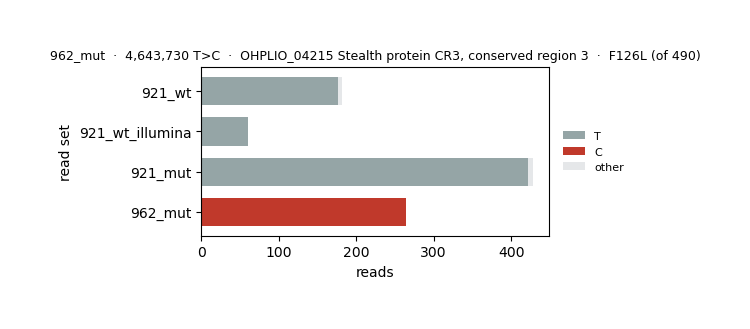

In [21]:
real = SUM[SUM.verdict == "real mutation"] if len(SUM) else SUM
for _, r in real.iterrows():
    ref_b, alt_b = parse_allele(r.allele)
    counts = []
    for k, bam in BAMS.items():
        d, c = pileup(bam, int(r.pos), int(r.pos))[int(r.pos)]
        counts.append({"read set": k, ref_b: c["REF"], alt_b: c[alt_b], "other": d - c["REF"] - c[alt_b]})
    cdf = pd.DataFrame(counts).set_index("read set")
    fig, ax = plt.subplots(figsize=(6, 2.6))
    cdf.plot.barh(stacked=True, ax=ax, color=["#95a5a6", C_REAL, "#e5e7e9"], width=0.7)
    ax.set_xlabel("reads"); ax.invert_yaxis()
    ax.set_title(f"{r.mutant}  ·  {r.pos:,} {r.allele}  ·  {r.locus} {r['product']}  ·  {r.aa_change}", fontsize=9)
    ax.legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.tight_layout(); fig.savefig(OUT / f"fig_mutation_{r.mutant}_{r.pos}.png", dpi=200)
    display(cdf)
    g = CDS[CDS.locus == r.locus].iloc[0]
    wt = REF_SEQ[g.start:g.end]; mu = apply(wt, int(r.pos) - 1 - g.start, ref_b, alt_b)
    if g.strand == -1:
        wt, mu = str(Seq(wt).reverse_complement()), str(Seq(mu).reverse_complement())
    pw, pm = str(Seq(wt).translate(table=11)), str(Seq(mu).translate(table=11))
    i = next(i for i, (x, y) in enumerate(zip(pw, pm)) if x != y)
    print(f"{r.locus}  aa {i - 14}-{i + 16}")
    print("parent ", pw[max(0, i - 15):i + 16]); print("mutant ", pm[max(0, i - 15):i + 16])
    print("        " + " " * min(15, i) + "^")

## 9. Interpretation

**1. Both picks are the right strain, intact, and not lysogens.** 99.7 % (921 r1) and 99.95 % (962 r1) of reads map to
the 9-2-1 parent; one closed chromosome each, colinear end to end with the parent; no Φ8 sequence anywhere (§2b).
Resistance by lysogeny / superinfection immunity and by large deletion (e.g. loss of a whole cassette) are both excluded.

**2. Almost every assembly-level difference is sequencing noise, not mutation.** Two assemblies of one clone already
differ at 11–48 sites (§3c), the same range as each mutant vs its own parent (16 for 921, 21 for 962). Against the reads (§4b):
- ~30 sites per lineage are **ONT systematic errors**: the allele sits at AF 0.3–0.5 in *every* ONT read set,
  parent included, and at 0 in Illumina. They are almost all C→T / G→A transitions — the signature of modified-base
  miscalls — and each assembler run picks a side at random.
- 9 sites are **parent-assembly errors**: Illumina shows the *mutant* assembly had the true base. That includes the
  site shared by both mutants but no parent (2,462,586), so it is not a convergent mutation.
- the rest are assembly-only indels absent from the reads.

**3. 9-6-2 r1 carries exactly one confirmed mutation, in a capsule-type polysaccharide cluster.**
`4,643,730 T>C` → **Stealth protein CR3 (OHPLIO_04215 / PICBEH_04214) F126L**, 490 aa. 263/264 mutant reads vs 0/176
parent ONT, 0/60 parent Illumina and 0/422 `921_mut` reads (§8b) — fixed in the clone, absent from the parent and from
the other lineage. It is the only read-confirmed change in either genome. The gene sits in the 4.64–4.67 Mb cluster
that opens with an ABC export system (permease + ATP-binding protein + outer-membrane polysaccharide export protein)
followed by sugar-phosphate / glycerol-phosphate enzymes (TagD, CDP-glycerol glycerophosphotransferase, CapA, XcbB/CpsF).
Stealth proteins are predicted sugar-1-phosphotransferases that build phosphodiester-linked capsule / exopolysaccharide
polymers (Sperisen et al. 2005, *PLoS Comput Biol* 1:e63, PMID 16299590). Whether F126 lies in a conserved catalytic region, and
whether F→L changes the polymer, is **not tested here**.

**4. 9-2-1 r1 has no confirmed mutation.** Three low-AF read-only calls (pth S75F, caiA D262N, lysR D10N; AF ≈ 0.30,
parent 0.07–0.10) are transitions with the same profile as the ONT errors in point 2 and are not trusted. Possible
explanations, not distinguishable with these data: the pick is not resistant (never phenotyped); resistance is not
genetic (e.g. transient / physiological); or the change lies where reads cannot resolve it (MAPQ < 20 repeats such as
rRNA operons, or a mixed culture below AF 0.3).

**5. The O-antigen cassette and the LPS core genes are untouched in both picks** (0 differences at assembly or read
level, §6). This does not rule out the O-antigen as Φ8's receptor — one clone can escape through many routes — but the
one resistance-associated change found points to the **capsule-type cluster**, not to the O-antigen named in
`code/0727_o_antigen_comparison/`. Both hypotheses stay open until phenotype + more clones.

**Cheapest next test:** PCR + Sanger of OHPLIO_04215 around 4,643,730 in 9-6-2 R1–R3 and 9-2-1 R1–R3 — confirms the
mutation independently of ONT and asks whether the other picks hit the same gene.

## UNDONE
- **Phenotype.** R1 picks have never been shown to be Φ8-resistant (spot / EOP on the sequenced clone). Without it, a
  clean genome cannot be read as “resistance without mutation”.
- **R2 / R3** of each host not sequenced — convergence across independent picks is the strongest test of a locus.
- **9-6-2 parent reads** not available; 9-2-1 parent reads stand in (same clone).
- **Sanger confirmation** of `4,643,730 T>C` (Stealth CR3) in 9-6-2 R1, and screening of the same gene in the other picks.
- **Functional test** of the capsule-type cluster (e.g. polysaccharide extraction / staining, or Φ8 adsorption on 9-6-2 R1).

---
_Log_
- 2026-10-10 — created. Inputs: SBYK6W (mutants, ONT), June parent assemblies, SRR39379361 (downloaded from ENA),
  3NKSC3 Illumina host reads. Result: one confirmed mutation (962 r1, Stealth CR3 F126L, capsule-type cluster); none in
  921 r1; O-antigen and LPS core unchanged in both; ~all other assembly differences are ONT errors.